# Forest Cover Type Classification with a Multilayer Perceptron (ANN)
**Deep Learning Assignment 1: MLP/ANN model development, fine-tuning and performance evaluation**

| Item | Choice |
|---|---|
| Problem | Predict the dominant tree species (forest cover type) of a 30 m x 30 m patch of forest from cartographic data |
| Task type | Multi-class **classification** (7 classes) |
| Dataset | UCI Covertype (Blackard & Dean), **581,012 records**, 54 raw input columns + 1 target |
| Model | Multilayer Perceptron (fully connected feed-forward network) in PyTorch |
| Model-selection metric | **Macro F1-score on the validation set** (the classes are heavily imbalanced) |

### Setup / how to run
1. Install Python 3.10+ and the packages: `python -m pip install -r requirements.txt`.
   README.md provides Windows virtual-environment instructions and the verified Python version.
2. Start Jupyter in this folder: `python -m notebook covertype_mlp.ipynb` (or open the file in VS Code).
3. Run all cells (*Kernel > Restart & Run All*). The dataset (about 11 MB) is downloaded automatically by
   scikit-learn into `./data/` on the first run.
4. Outputs are written to `./figures/` (plots), `./results/` (experiment tables) and `./models/` (final model).

A full run takes roughly 40-60 minutes on a laptop CPU (no GPU needed). The tuning experiments of each group
are trained in parallel worker processes to keep the run time reasonable.

### Notebook outline
1. Problem definition and dataset
2. Exploratory data analysis (EDA)
3. Data preprocessing (cleaning, encoding, outliers, splitting, scaling, class imbalance)
4. MLP model, training loop and evaluation helpers
5. Baseline model
6. Fine-tuning experiments (controlled groups with explicit configuration changes)
7. Final model: early stopping and longer training
8. Final evaluation on the held-out test set
9. Experiment comparison, conclusions, limitations and future work

## 0. Imports and global settings
All libraries used in the project are imported here. A fixed random seed makes the data split, weight
initialisation and mini-batch shuffling reproducible, so differences between experiments come from the
configuration change and not from luck.

In [1]:
import os                      # folders and CPU count
import time                    # timing the training runs
import copy                    # deep copies of model weights (early stopping)
import random                  # Python random seed
import warnings

import numpy as np             # numerical arrays
import pandas as pd            # tables / data frames
import matplotlib.pyplot as plt  # all plots
from IPython.display import display  # show tables nicely in the notebook
from forest_cover import MLP, engineer_features, fit_training_medians, impute_continuous

import torch                   # deep learning framework
import torch.nn as nn          # layers, activations, loss functions

from joblib import Parallel, delayed  # run several experiments at the same time (one CPU core each)

from sklearn.datasets import fetch_covtype              # downloads the UCI Covertype dataset
from sklearn.model_selection import train_test_split    # stratified train/val/test split
from sklearn.preprocessing import StandardScaler        # z-score feature scaling
from sklearn.utils.class_weight import compute_class_weight  # weights for class imbalance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_auc_score, roc_curve)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

SEED = 42  # one seed for everything -> reproducible results


def set_seed(seed=SEED):
    """Seed Python, NumPy and PyTorch random number generators."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()

# Folders for downloaded data and generated outputs
for folder in ["data", "figures", "results", "models"]:
    os.makedirs(folder, exist_ok=True)

# Plot style used by all figures
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

print("PyTorch", torch.__version__, "| NumPy", np.__version__, "| pandas", pd.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch 2.15.0+cpu | NumPy 2.5.1 | pandas 3.0.5
CUDA available: False


## 1. Problem definition and dataset

### 1.1 Problem statement and real-world relevance
Forest managers (for example the US Forest Service) need to know **which tree species dominate each part of a
forest**. This "forest cover type" inventory is used for wildfire risk planning, wildlife habitat management,
timber planning and ecological monitoring. Measuring it by field surveys or interpreting aerial imagery is
slow and expensive, especially for remote wilderness. Cartographic variables (elevation, slope, distances to
water and roads, soil type, ...) are already available for the whole area from GIS data, so a model that
predicts cover type from these variables gives a cheap, fast estimate for land that has not been surveyed.

**Goal:** given the cartographic description of a 30 m x 30 m cell, predict which of 7 cover types it has.
This is a **multi-class classification** problem: the target is a category, not a number.

### 1.2 Dataset source
* **UCI Machine Learning Repository - Covertype** (Blackard, J. A. & Dean, D. J., Colorado State University,
  1998): https://archive.ics.uci.edu/dataset/31/covertype
* Cells come from four wilderness areas of the **Roosevelt National Forest, northern Colorado**, areas with
  little human disturbance, so the cover type reflects natural ecological processes.
* Cover type labels come from US Forest Service (USFS) Region 2 Resource Information System data; the
  inputs come from US Geological Survey (USGS) and USFS data.
* Loaded here with `sklearn.datasets.fetch_covtype`, which downloads the original UCI file.
* **581,012 records**, comfortably above the 50,000-record minimum.

### 1.3 Features and target
| Feature | Type | Meaning |
|---|---|---|
| `Elevation` | numeric (m) | height above sea level |
| `Aspect` | numeric (degrees 0-360) | compass direction the slope faces |
| `Slope` | numeric (degrees) | steepness of the terrain |
| `Horizontal_Distance_To_Hydrology` | numeric (m) | horizontal distance to the nearest surface water |
| `Vertical_Distance_To_Hydrology` | numeric (m) | height above (+) or below (-) the nearest surface water |
| `Horizontal_Distance_To_Roadways` | numeric (m) | distance to the nearest road |
| `Hillshade_9am`, `Hillshade_Noon`, `Hillshade_3pm` | numeric (0-255) | amount of sunlight on the cell at the summer solstice |
| `Horizontal_Distance_To_Fire_Points` | numeric (m) | distance to the nearest wildfire ignition point |
| `Wilderness_Area_0..3` | 4 binary (one-hot) | Rawah, Neota, Comanche Peak, Cache la Poudre |
| `Soil_Type_0..39` | 40 binary (one-hot) | USFS soil type (Ecological Landtype Unit) |
| **`Cover_Type`** (target) | categorical 1-7 | 1 Spruce/Fir, 2 Lodgepole Pine, 3 Ponderosa Pine, 4 Cottonwood/Willow, 5 Aspen, 6 Douglas-fir, 7 Krummholz |

In [2]:
# Download (first run only) and load the dataset as a pandas DataFrame
covtype = fetch_covtype(data_home="data", as_frame=True)
df = covtype.frame.copy()
df["Cover_Type"] = df["Cover_Type"].astype(int)

CLASS_NAMES = {1: "Spruce/Fir", 2: "Lodgepole Pine", 3: "Ponderosa Pine", 4: "Cottonwood/Willow",
               5: "Aspen", 6: "Douglas-fir", 7: "Krummholz"}

# Column groups used throughout the notebook
CONT_RAW = ["Elevation", "Aspect", "Slope", "Horizontal_Distance_To_Hydrology",
            "Vertical_Distance_To_Hydrology", "Horizontal_Distance_To_Roadways",
            "Hillshade_9am", "Hillshade_Noon", "Hillshade_3pm", "Horizontal_Distance_To_Fire_Points"]
WILD_COLS = [c for c in df.columns if c.startswith("Wilderness_Area")]
SOIL_COLS = [c for c in df.columns if c.startswith("Soil_Type")]
TARGET = "Cover_Type"

print("Shape (rows, columns):", df.shape)
print(f"{len(CONT_RAW)} continuous + {len(WILD_COLS)} wilderness + {len(SOIL_COLS)} soil columns + 1 target")
df.head()

Shape (rows, columns): (581012, 55)
10 continuous + 4 wilderness + 40 soil columns + 1 target


,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,Wilderness_Area_0,Wilderness_Area_1,Wilderness_Area_2,Wilderness_Area_3,Soil_Type_0,Soil_Type_1,Soil_Type_2,Soil_Type_3,Soil_Type_4,Soil_Type_5,Soil_Type_6,Soil_Type_7,Soil_Type_8,Soil_Type_9,Soil_Type_10,Soil_Type_11,Soil_Type_12,Soil_Type_13,Soil_Type_14,Soil_Type_15,Soil_Type_16,Soil_Type_17,Soil_Type_18,Soil_Type_19,Soil_Type_20,Soil_Type_21,Soil_Type_22,Soil_Type_23,Soil_Type_24,Soil_Type_25,Soil_Type_26,Soil_Type_27,Soil_Type_28,Soil_Type_29,Soil_Type_30,Soil_Type_31,Soil_Type_32,Soil_Type_33,Soil_Type_34,Soil_Type_35,Soil_Type_36,Soil_Type_37,Soil_Type_38,Soil_Type_39,Cover_Type
0,2596.0,51.0,3.0,258.0,0.0,510.0,221.0,232.0,148.0,6279.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5
1,2590.0,56.0,2.0,212.0,-6.0,390.0,220.0,235.0,151.0,6225.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5
2,2804.0,139.0,9.0,268.0,65.0,3180.0,234.0,238.0,135.0,6121.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
3,2785.0,155.0,18.0,242.0,118.0,3090.0,238.0,238.0,122.0,6211.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
4,2595.0,45.0,2.0,153.0,-1.0,391.0,220.0,234.0,150.0,6172.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5


## 2. Exploratory data analysis (EDA)
### 2.1 Data types, summary statistics, missing values and duplicates

In [3]:
print("Column dtypes:\n", df.dtypes.value_counts(), "\n")
print("Total missing values:", int(df.isna().sum().sum()))
print("Fully duplicated rows:", int(df.duplicated().sum()))
print("Rows with identical features but a different label:",
      int(df.duplicated(subset=CONT_RAW + WILD_COLS + SOIL_COLS).sum() - df.duplicated().sum()))
df[CONT_RAW].describe().T.round(1)

Column dtypes:
 float64    54
int64       1
Name: count, dtype: int64 

Total missing values: 0


Fully duplicated rows: 0


Rows with identical features but a different label: 0


,count,mean,std,min,25%,50%,75%,max
Elevation,581012.0,2959.4,280.0,1859.0,2809.0,2996.0,3163.0,3858.0
Aspect,581012.0,155.7,111.9,0.0,58.0,127.0,260.0,360.0
Slope,581012.0,14.1,7.5,0.0,9.0,13.0,18.0,66.0
Horizontal_Distance_To_Hydrology,581012.0,269.4,212.5,0.0,108.0,218.0,384.0,1397.0
Vertical_Distance_To_Hydrology,581012.0,46.4,58.3,-173.0,7.0,30.0,69.0,601.0
Horizontal_Distance_To_Roadways,581012.0,2350.1,1559.3,0.0,1106.0,1997.0,3328.0,7117.0
Hillshade_9am,581012.0,212.1,26.8,0.0,198.0,218.0,231.0,254.0
Hillshade_Noon,581012.0,223.3,19.8,0.0,213.0,226.0,237.0,254.0
Hillshade_3pm,581012.0,142.5,38.3,0.0,119.0,143.0,168.0,254.0
Horizontal_Distance_To_Fire_Points,581012.0,1980.3,1324.2,0.0,1024.0,1710.0,2550.0,7173.0


### 2.2 Target distribution (class balance)

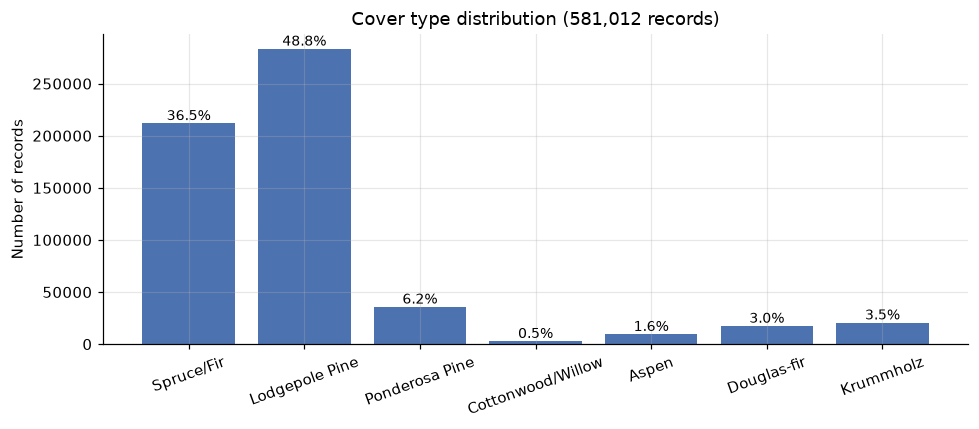

Imbalance ratio (largest / smallest class): 103 : 1


In [4]:
counts = df[TARGET].value_counts().sort_index()
pct = 100 * counts / counts.sum()
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar([CLASS_NAMES[i] for i in counts.index], counts.values, color="#4C72B0")
for b, p in zip(bars, pct.values):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{p:.1f}%", ha="center", va="bottom", fontsize=9)
ax.set_title("Cover type distribution (581,012 records)")
ax.set_ylabel("Number of records")
plt.xticks(rotation=20)
plt.tight_layout(); plt.savefig("figures/eda_class_distribution.png"); plt.show()
print("Imbalance ratio (largest / smallest class): %.0f : 1" % (counts.max() / counts.min()))

### 2.3 Distributions of the continuous features

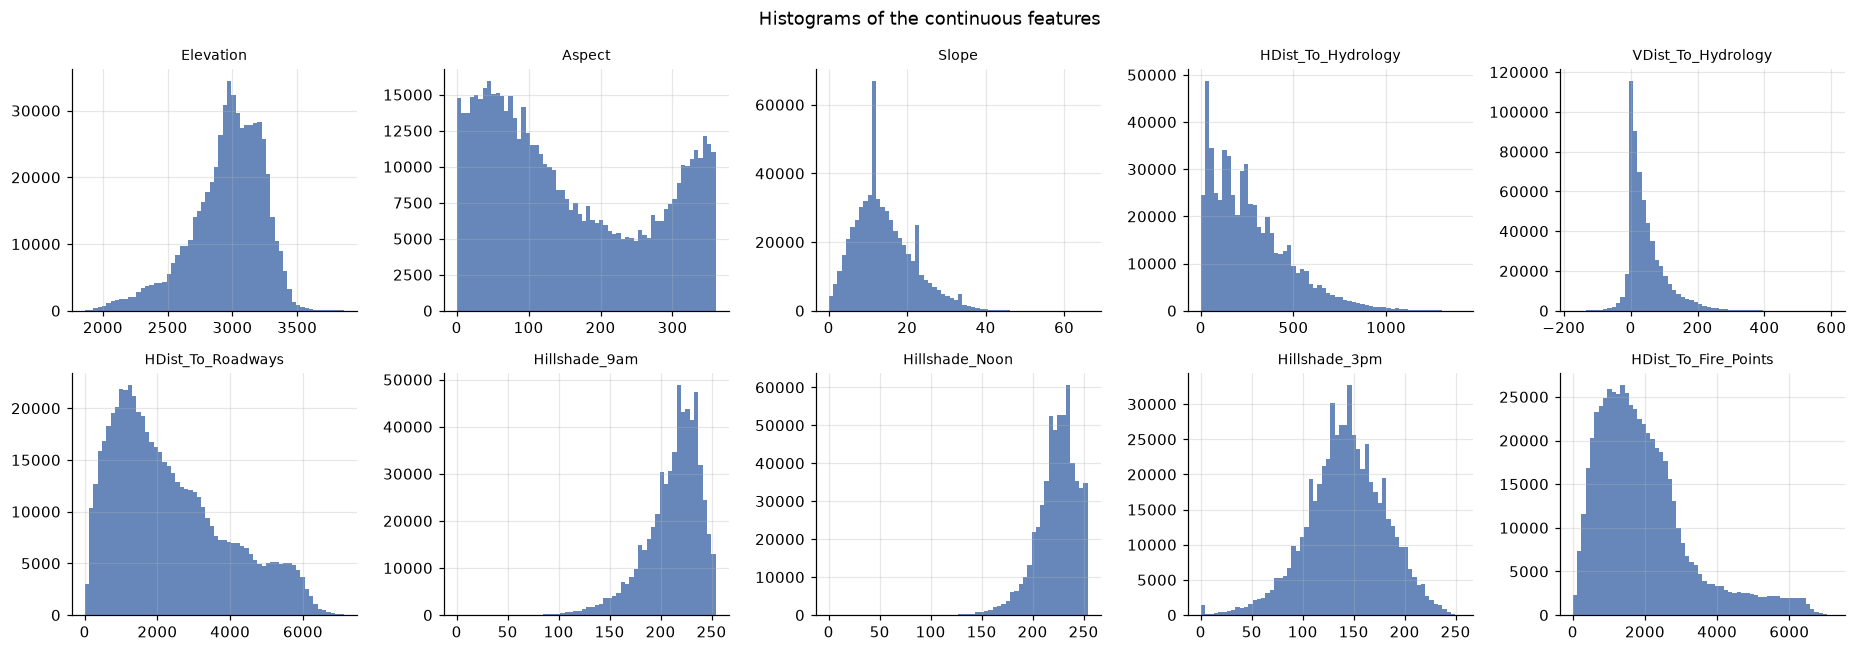

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(17, 6))
for ax, col in zip(axes.ravel(), CONT_RAW):
    ax.hist(df[col], bins=60, color="#4C72B0", alpha=0.85)
    ax.set_title(col.replace("Horizontal_Distance", "HDist").replace("Vertical_Distance", "VDist"), fontsize=9)
plt.suptitle("Histograms of the continuous features")
plt.tight_layout(); plt.savefig("figures/eda_histograms.png"); plt.show()

### 2.4 Relationship between features and the target

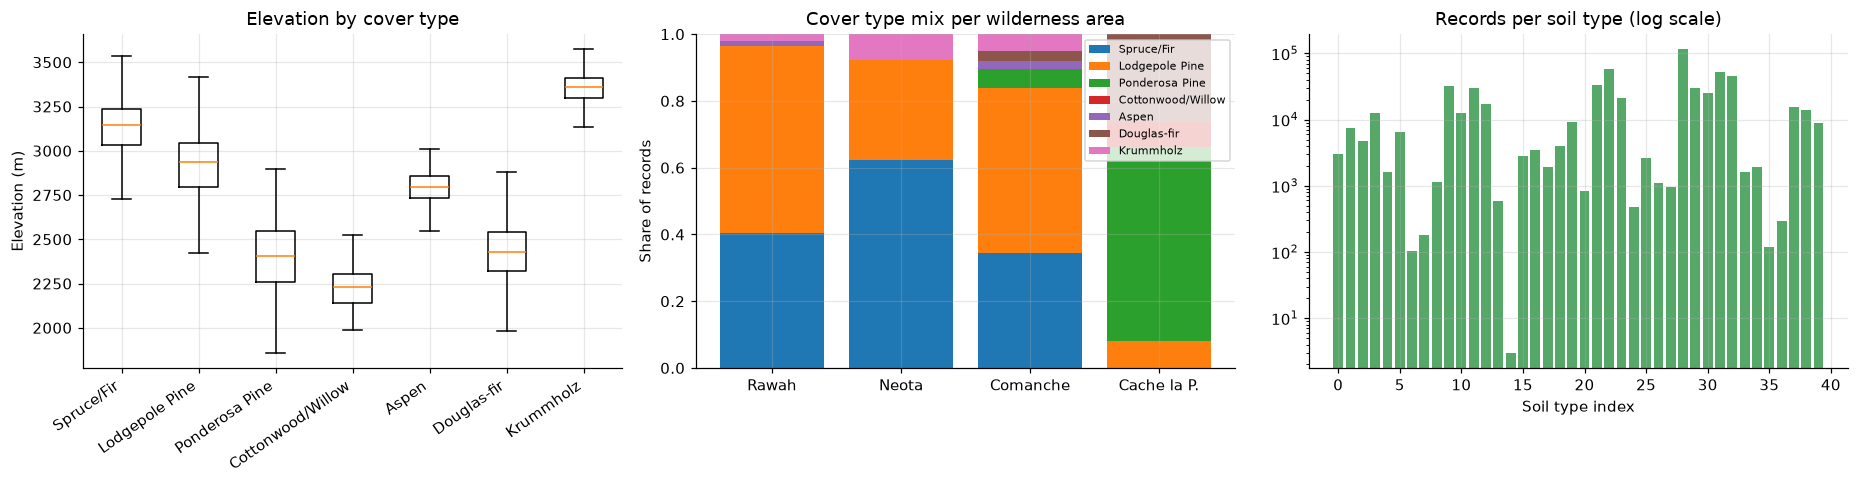

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
# Elevation per class: the strongest single predictor in this dataset
data_by_class = [df.loc[df[TARGET] == k, "Elevation"].values for k in sorted(CLASS_NAMES)]
axes[0].boxplot(data_by_class, showfliers=False)
axes[0].set_xticks(range(1, 8)); axes[0].set_xticklabels([CLASS_NAMES[k] for k in sorted(CLASS_NAMES)], rotation=35, ha="right")
axes[0].set_title("Elevation by cover type"); axes[0].set_ylabel("Elevation (m)")

# Wilderness area vs cover type (decode the one-hot columns back to one category for plotting)
wild = pd.Series(np.argmax(df[WILD_COLS].values, axis=1), name="Wilderness")
ct = pd.crosstab(wild, df[TARGET], normalize="index")
bottom = np.zeros(len(ct))
for k in ct.columns:
    axes[1].bar(["Rawah", "Neota", "Comanche", "Cache la P."], ct[k].values, bottom=bottom, label=CLASS_NAMES[k])
    bottom += ct[k].values
axes[1].set_title("Cover type mix per wilderness area"); axes[1].set_ylabel("Share of records")
axes[1].legend(fontsize=7, loc="upper right")

# How many records each soil type has
soil_counts = df[SOIL_COLS].sum().values
axes[2].bar(range(40), soil_counts, color="#55A868")
axes[2].set_yscale("log"); axes[2].set_title("Records per soil type (log scale)"); axes[2].set_xlabel("Soil type index")
plt.tight_layout(); plt.savefig("figures/eda_feature_vs_target.png"); plt.show()

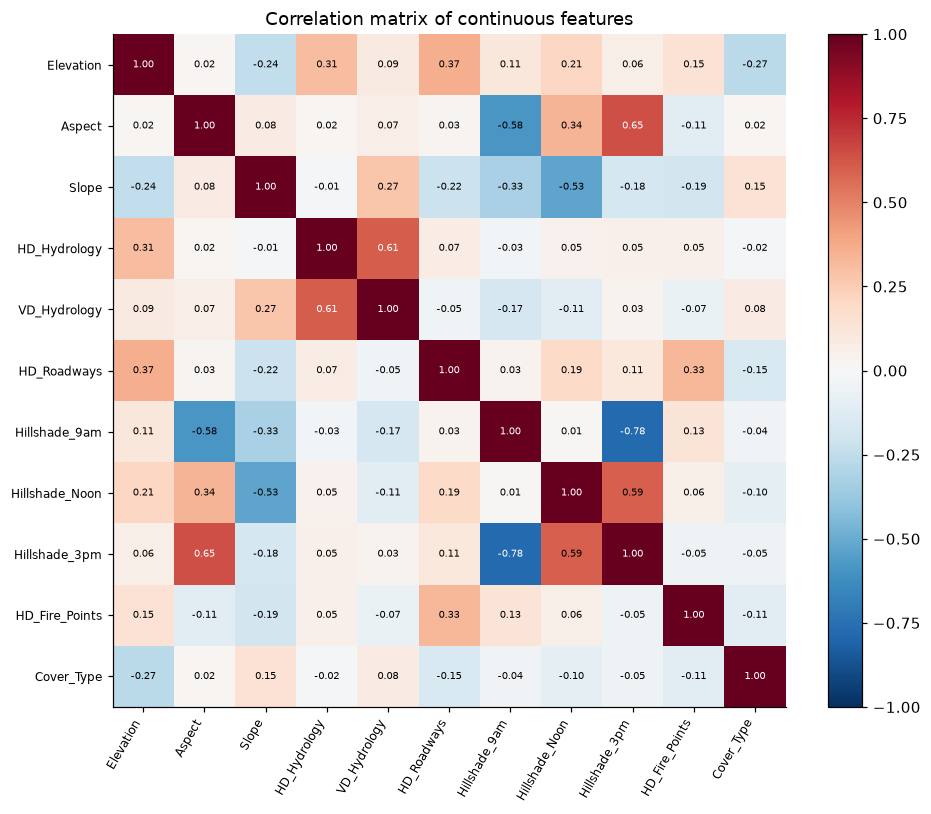

In [7]:
# Pearson correlation between the continuous features (and the target, for a rough indication only)
corr = df[CONT_RAW + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
short = [c.replace("Horizontal_Distance_To_", "HD_").replace("Vertical_Distance_To_", "VD_") for c in corr.columns]
ax.set_xticks(range(len(short))); ax.set_xticklabels(short, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(short))); ax.set_yticklabels(short, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
ax.grid(False); plt.colorbar(im, fraction=0.046)
ax.set_title("Correlation matrix of continuous features")
plt.tight_layout(); plt.savefig("figures/eda_correlation.png"); plt.show()

### EDA observations
The data contains 581,012 rows, 54 inputs and one target, with no missing values, exact duplicates, or
identical feature rows carrying conflicting labels. Lodgepole Pine (48.76%) and Spruce/Fir (36.46%) together
account for 85.22% of records; Cottonwood/Willow is only 0.47%, giving an imbalance ratio of about 103:1.
Accuracy alone could hide failures on minority species, so validation macro F1 drives model selection.
Elevation ranges from 1,859 to 3,858 m and differs across species in the class-wise boxplots. Several distance
features have long right tails, whereas the hillshade measurements have a bounded physical range.
Continuous features therefore need scaling, and extreme distances are clipped rather than deleted.
Aspect is circular: 0 and 360 degrees represent the same direction, motivating sine/cosine features.
Negative vertical distance to water is valid (the cell can be below the water source).
The target is nominal: Pearson correlation with numeric cover-type IDs is only a rough visualization,
not evidence of an ordered target or a reason to select/drop a feature.

## 3. Data preprocessing
### 3.1 Missing values, duplicates and inconsistent data
* **Missing values:** there are none in the supplied dataset. If continuous measurements were missing,
  they would stay missing through feature engineering and be filled using medians fitted after splitting
  in section 3.3. Invalid or missing categorical indicators are rejected rather than median-imputed.
* **Duplicates:** exact duplicate rows add no information and would let the same record appear in both the
  training and test set, so they are dropped.
* **Consistency rules** derived from the dataset documentation are checked: each record must belong to exactly
  one wilderness area and one soil type (one-hot groups sum to 1), hillshade must be in 0-255, aspect in
  0-360 degrees, slope and horizontal distances non-negative.

In [8]:
n_before = len(df)

# Keep continuous NaNs until the training split is available; never fit an imputer on the full dataset.

# Exact duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

checks = {
    "Wilderness one-hot does not sum to 1": int((df[WILD_COLS].sum(axis=1) != 1).sum()),
    "Soil one-hot does not sum to 1": int((df[SOIL_COLS].sum(axis=1) != 1).sum()),
    "Hillshade outside 0-255": int(((df[["Hillshade_9am", "Hillshade_Noon", "Hillshade_3pm"]] < 0) |
                                     (df[["Hillshade_9am", "Hillshade_Noon", "Hillshade_3pm"]] > 255)).any(axis=1).sum()),
    "Aspect outside [0, 360)": int(((df["Aspect"] < 0) | (df["Aspect"] >= 360)).sum()),
    "Negative slope": int((df["Slope"] < 0).sum()),
    "Negative horizontal distance": int((df[["Horizontal_Distance_To_Hydrology", "Horizontal_Distance_To_Roadways",
                                             "Horizontal_Distance_To_Fire_Points"]] < 0).any(axis=1).sum()),
}
display(pd.DataFrame({"violations": checks}))

# Drop invalid categorical rows. The feature helper below maps valid 360-degree aspect to 0 and rejects
# other invalid physical ranges; continuous NaNs remain for train-only imputation.
valid = (df[WILD_COLS + SOIL_COLS].isin([0, 1]).all(axis=1)
         & (df[WILD_COLS].sum(axis=1) == 1) & (df[SOIL_COLS].sum(axis=1) == 1))
df = df[valid].reset_index(drop=True)

# Binary columns stored as small integers
df[WILD_COLS + SOIL_COLS] = df[WILD_COLS + SOIL_COLS].astype(np.int8)
print(f"Rows before cleaning: {n_before:,} | after cleaning: {len(df):,}")

,violations
Wilderness one-hot does not sum to 1,0
Soil one-hot does not sum to 1,0
Hillshade outside 0-255,0
"Aspect outside [0, 360)",51
Negative slope,0
Negative horizontal distance,0


Rows before cleaning: 581,012 | after cleaning: 581,012


### 3.2 Feature engineering and categorical encoding
* **Categorical inputs.** `Wilderness_Area` (4 categories) and `Soil_Type` (40 categories) are nominal, they
  have no order. They are already **one-hot encoded** in the source (one 0/1 column per category), which is the
  right encoding for an MLP: a single integer code (0..39) would wrongly tell the network that soil 39 is
  "bigger" than soil 1. They are kept as 0/1 columns and are not scaled.
* **Cyclic encoding of `Aspect`.** Aspect is an angle: 359 degrees and 1 degree are almost the same direction
  but numerically far apart. It is replaced by `sin(aspect)` and `cos(aspect)`, which puts neighbouring
  directions close together.
* **Euclidean distance to water**, combining the horizontal and vertical distance into one physical distance.
* **Target encoding.** Labels 1..7 are mapped to 0..6 because PyTorch's `CrossEntropyLoss` expects class
  indices starting at 0.

In [9]:
# The shared helper validates physical ranges and creates Aspect_sin, Aspect_cos, and Euclidean distance.
# Inference calls the same helper, so feature names, formulas, and ordering stay consistent.
df = engineer_features(df)

CONT_COLS = [c for c in CONT_RAW if c != "Aspect"] + ["Aspect_sin", "Aspect_cos", "Euclid_Distance_To_Hydrology"]
BIN_COLS = WILD_COLS + SOIL_COLS
FEATURES = CONT_COLS + BIN_COLS

X_all = df[FEATURES]
y_all = (df[TARGET] - 1).values.astype(np.int64)   # 1..7 -> 0..6
N_FEATURES, N_CLASSES = len(FEATURES), len(CLASS_NAMES)
LABELS = [CLASS_NAMES[k] for k in sorted(CLASS_NAMES)]
print(f"Input features: {N_FEATURES} ({len(CONT_COLS)} continuous + {len(BIN_COLS)} binary) | classes: {N_CLASSES}")

Input features: 56 (12 continuous + 44 binary) | classes: 7


### 3.3 Train / validation / test split (70% / 15% / 15%)
| Split | Purpose |
|---|---|
| **Training (70%)** | the only data the network learns its weights from; also used to fit the scaler, outlier limits and class weights |
| **Validation (15%)** | compares experiments, picks hyper-parameters and triggers early stopping |
| **Test (15%)** | touched only once, at the very end, to report an unbiased estimate of real-world performance |

The split is **stratified** on the target so every split keeps the same class proportions; this matters for
the rare Cottonwood/Willow class (0.5% of the data).

**Leakage prevention:** the data is split *before* any statistic is computed. The outlier clipping limits, the
imputation medians, mean and standard deviation of the scaler and class weights are computed on training only and
then applied unchanged to validation and test, so no information from validation/test leaks into training.

In [10]:
X_train_df, X_temp_df, y_train, y_temp = train_test_split(
    X_all, y_all, test_size=0.30, stratify=y_all, random_state=SEED)
X_val_df, X_test_df, y_val, y_test = train_test_split(
    X_temp_df, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

TRAIN_MEDIANS = fit_training_medians(X_train_df, CONT_COLS)
X_train_df, X_val_df, X_test_df = (
    impute_continuous(frame, TRAIN_MEDIANS) for frame in (X_train_df, X_val_df, X_test_df)
)

split_table = pd.DataFrame({
    "records": [len(y_train), len(y_val), len(y_test)],
    **{name: [np.mean(y == k) * 100 for y in (y_train, y_val, y_test)] for k, name in enumerate(LABELS)}
}, index=["train", "validation", "test"]).round(2)
split_table

,records,Spruce/Fir,Lodgepole Pine,Ponderosa Pine,Cottonwood/Willow,Aspen,Douglas-fir,Krummholz
train,406708,36.46,48.76,6.15,0.47,1.63,2.99,3.53
validation,87152,36.46,48.76,6.15,0.47,1.63,2.99,3.53
test,87152,36.46,48.76,6.15,0.47,1.63,2.99,3.53


### 3.4 Outliers
The IQR rule (values below Q1 - 1.5 IQR or above Q3 + 1.5 IQR) is used to count outliers in each continuous
feature. These values are real terrain measurements (for example cells far from a road), not data-entry
errors, so deleting them would throw away valid, rare situations. Instead they are **clipped (winsorised)**
to the 0.5th and 99.5th percentiles of the training set. This keeps every record but stops a few extreme
values from dominating the scaled inputs and producing large activations early in training.

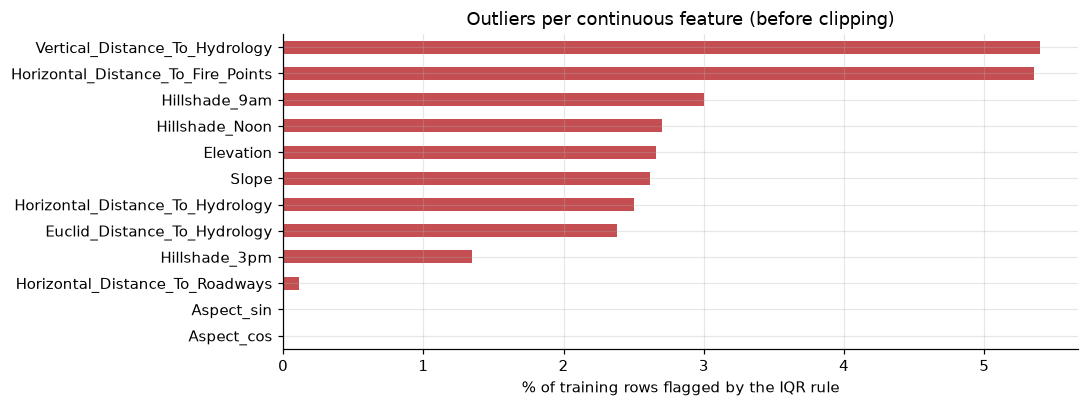

In [11]:
q1, q3 = X_train_df[CONT_COLS].quantile(0.25), X_train_df[CONT_COLS].quantile(0.75)
iqr = q3 - q1
outlier_share = (((X_train_df[CONT_COLS] < q1 - 1.5 * iqr) | (X_train_df[CONT_COLS] > q3 + 1.5 * iqr)).mean() * 100)

LOW = X_train_df[CONT_COLS].quantile(0.005)    # clipping limits learned on TRAIN only
HIGH = X_train_df[CONT_COLS].quantile(0.995)


def clip_outliers(frame):
    """Winsorise continuous columns with the training-set limits."""
    frame = frame.copy()
    frame[CONT_COLS] = frame[CONT_COLS].clip(lower=LOW, upper=HIGH, axis=1)
    return frame


X_train_df, X_val_df, X_test_df = map(clip_outliers, (X_train_df, X_val_df, X_test_df))

fig, ax = plt.subplots(figsize=(10, 3.8))
outlier_share.sort_values().plot.barh(ax=ax, color="#C44E52")
ax.set_xlabel("% of training rows flagged by the IQR rule"); ax.set_title("Outliers per continuous feature (before clipping)")
plt.tight_layout(); plt.savefig("figures/prep_outliers.png"); plt.show()

### 3.5 Feature scaling
The continuous features have very different ranges (elevation about 1,900-3,800, aspect sin/cos -1..1, road
distance up to about 7,000). Gradient descent converges much faster when inputs have similar scale, so each
continuous feature is **standardised** to mean 0 and standard deviation 1 with a `StandardScaler` fitted on the
training set. The binary one-hot columns are already 0/1 and are left unchanged.

In [12]:
scaler = StandardScaler().fit(X_train_df[CONT_COLS])   # learns mean / std from TRAIN only


def to_matrix(frame):
    """Scale continuous columns and return a float32 NumPy matrix in FEATURES order."""
    cont = scaler.transform(frame[CONT_COLS])
    return np.hstack([cont, frame[BIN_COLS].values]).astype(np.float32)


X_train, X_val, X_test = to_matrix(X_train_df), to_matrix(X_val_df), to_matrix(X_test_df)
print("X_train", X_train.shape, "| X_val", X_val.shape, "| X_test", X_test.shape)
print("Train mean of scaled continuous features (should be ~0):", X_train[:, :len(CONT_COLS)].mean(0).round(3)[:5])
print("Validation mean (close to 0 but not exactly, as expected):", X_val[:, :len(CONT_COLS)].mean(0).round(3)[:5])

X_train (406708, 56) | X_val (87152, 56) | X_test (87152, 56)
Train mean of scaled continuous features (should be ~0): [ 0.  0. -0. -0.  0.]
Validation mean (close to 0 but not exactly, as expected): [-0.006 -0.005 -0.003 -0.006 -0.001]


### 3.6 Class imbalance
The largest class has about 100 times more records than the smallest. A network trained with plain
cross-entropy mostly optimises the two big classes. Two options are prepared (and tested in experiment group H):
* **balanced weights**: `w_c = N / (K * N_c)`, the standard inverse-frequency weighting;
* **square-root weights**: `sqrt` of the balanced weights, a softer version that boosts rare classes without
  making the loss dominated by a few hundred Cottonwood/Willow records.

Imbalance is also handled in evaluation: models are compared with **macro F1**, which gives every class
equal importance, instead of accuracy alone.

In [13]:
balanced_w = compute_class_weight("balanced", classes=np.arange(N_CLASSES), y=y_train)
CLASS_WEIGHTS = {"balanced": balanced_w.astype(np.float32),
                 "sqrt": np.sqrt(balanced_w).astype(np.float32)}
pd.DataFrame({"train share %": np.bincount(y_train) / len(y_train) * 100,
              "balanced weight": balanced_w, "sqrt weight": np.sqrt(balanced_w)}, index=LABELS).round(3)

,train share %,balanced weight,sqrt weight
Spruce/Fir,36.461,0.392,0.626
Lodgepole Pine,48.760,0.293,0.541
Ponderosa Pine,6.154,2.321,1.524
Cottonwood/Willow,0.473,30.214,5.497
Aspen,1.634,8.744,2.957
Douglas-fir,2.989,4.779,2.186
Krummholz,3.530,4.047,2.012


## 4. MLP model, training loop and evaluation helpers

### 4.1 Architecture
* **Input layer:** 56 neurons, one per feature (12 scaled continuous + 4 wilderness + 40 soil columns).
* **Hidden layers:** fully connected (`nn.Linear`) layers. Each computes `z = W x + b` and applies a
  non-linear activation `a = f(z)`. Without the non-linearity, any number of layers would collapse into a
  single linear model. Optional **Batch Normalisation** (after the linear layer, before the activation) and
  **Dropout** (after the activation) are used in the fine-tuning experiments.
* **Output layer:** 7 neurons, one per cover type. They output raw scores (*logits*); **softmax**
  `p_k = exp(z_k) / sum_j exp(z_j)` turns them into class probabilities that sum to 1.
* **Loss:** **categorical cross-entropy** `L = -log p_true_class`, the standard loss for multi-class
  classification (the negative log-likelihood of the correct class). PyTorch's `nn.CrossEntropyLoss` applies
  log-softmax internally, which is why the network outputs logits and has no explicit softmax layer
  (numerically more stable). It accepts optional class weights for the imbalance experiments.

### 4.2 Forward propagation and training
1. **Forward pass:** a mini-batch `X` (batch x 56) goes through every layer: `h1 = f(W1 X + b1)`,
   `h2 = f(W2 h1 + b2)`, ..., `logits = W_out h_last + b_out`.
2. **Loss:** cross-entropy between the logits and the true labels, averaged over the batch (plus an L1 penalty
   if enabled).
3. **Backward pass (backpropagation):** `loss.backward()` uses the chain rule to compute the gradient of the
   loss with respect to every weight and bias.
4. **Update:** the optimizer (SGD, RMSprop, Adam or AdamW) moves each parameter a small step against its
   gradient, scaled by the learning rate.
5. One pass over all mini-batches is an **epoch**. After each epoch the model is evaluated on the validation set
   (loss, accuracy, macro F1); this history is used for the learning curves and for early stopping.

### 4.3 Weight initialisation
* **He / Kaiming normal** (baseline): variance `2 / fan_in`, designed for ReLU-type activations so that the
  signal neither vanishes nor explodes through the layers.
* **Xavier / Glorot uniform**: variance `2 / (fan_in + fan_out)`, designed for tanh/sigmoid.
* **Small normal N(0, 0.01)**: a naive choice, included to show why principled initialisation matters.
* **PyTorch default** (Kaiming-uniform with a=sqrt(5)).
Biases start at zero for the explicit He, Xavier and small-normal schemes. The default option retains
PyTorch's built-in bias initialization as well as its weight initialization.

In [14]:
# MLP is imported from forest_cover.py; training and inference share its layer order and initialization.
# Hidden blocks: Linear -> optional BatchNorm -> activation -> optional Dropout.
# Its forward method passes inputs through those blocks and returns the seven output logits.

# Quick look at the baseline architecture and its number of trainable parameters
_demo = MLP(N_FEATURES, N_CLASSES, hidden=(64, 32))
print(_demo)
print("Trainable parameters:", sum(p.numel() for p in _demo.parameters() if p.requires_grad))

MLP(
  (net): Sequential(
    (0): Linear(in_features=56, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=7, bias=True)
  )
)
Trainable parameters: 5959


### 4.4 Training configuration
Every experiment is described by a configuration dictionary. `BASE_CONFIG` is the **baseline**: a deliberately
simple, standard starting point. Fine-tuning experiments change one or a few keys at a time.

| Key | Baseline | Meaning |
|---|---|---|
| `hidden` | (64, 32) | 2 hidden layers with 64 and 32 neurons |
| `activation` | ReLU | hidden-layer activation |
| `init` | He normal | weight initialisation |
| `optimizer`, `lr`, `momentum` | SGD, 0.01, 0 | plain mini-batch stochastic gradient descent |
| `batch_size` | 512 | records per gradient update |
| `epochs` | 20 | passes over the training set |
| `dropout`, `batch_norm`, `weight_decay`, `l1` | off | regularisation |
| `scheduler` | none | learning-rate schedule |
| `class_weight` | none | imbalance handling |
| `early_stopping`, `patience` | off, 8 | stop when validation loss has not improved for `patience` epochs |

In [15]:
BASE_CONFIG = dict(
    hidden=(64, 32), activation="relu", init="he",
    dropout=0.0, batch_norm=False, weight_decay=0.0, l1=0.0,
    optimizer="sgd", lr=0.01, momentum=0.0, scheduler=None,
    batch_size=512, epochs=20,
    class_weight=None, early_stopping=False, patience=8,
)


def make_optimizer(model, cfg):
    """Create the optimizer named in the config.
    SGD     : w <- w - lr * grad (optionally with momentum, a running average of past gradients)
    RMSprop : divides the step by a running average of squared gradients (per-parameter step size)
    Adam    : momentum + RMSprop-style scaling, with bias correction
    AdamW   : Adam with weight decay decoupled from the gradient update (better-behaved L2 regularisation)
    For SGD/RMSprop/Adam, weight_decay is classic L2 regularisation added to the gradient."""
    params, lr, wd = model.parameters(), cfg["lr"], cfg["weight_decay"]
    if cfg["optimizer"] == "sgd":
        return torch.optim.SGD(params, lr=lr, momentum=cfg["momentum"], weight_decay=wd)
    if cfg["optimizer"] == "rmsprop":
        return torch.optim.RMSprop(params, lr=lr, weight_decay=wd)
    if cfg["optimizer"] == "adam":
        return torch.optim.Adam(params, lr=lr, weight_decay=wd)
    if cfg["optimizer"] == "adamw":
        return torch.optim.AdamW(params, lr=lr, weight_decay=wd)
    raise ValueError(cfg["optimizer"])


def make_scheduler(optimizer, cfg, steps_per_epoch):
    """Learning-rate schedules:
    cosine   : lr decays smoothly from lr to ~0 following a cosine curve over all epochs
    onecycle : lr warms up to lr then anneals to almost 0 (updated every batch)
    plateau  : lr is halved when validation loss stops improving for 2 epochs"""
    s = cfg["scheduler"]
    if s is None:
        return None
    if s == "cosine":
        return torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg["epochs"])
    if s == "onecycle":
        return torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=cfg["lr"], epochs=cfg["epochs"],
                                                   steps_per_epoch=steps_per_epoch)
    if s == "plateau":
        return torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)
    raise ValueError(s)


@torch.no_grad()
def predict_logits(model, X, batch=16384):
    """Forward pass in evaluation mode (dropout off, BatchNorm uses running statistics)."""
    model.eval()
    return torch.cat([model(X[i:i + batch]) for i in range(0, len(X), batch)])


LOG_FILE = "results/training_log.txt"   # one line per epoch of every run (handy to follow long runs)


def as_tensor(a):
    """NumPy array -> PyTorch tensor without an extra copy within this worker process."""
    return torch.from_numpy(np.asarray(a))


def train_model(cfg, data, verbose=False, run_name="run"):
    """Train one MLP with configuration `cfg`.

    data: dict with NumPy arrays X_train, y_train, X_val, y_val, X_mon, y_mon (X_mon/y_mon is a fixed
          50k-row subset of the training set used to track the training loss/accuracy each epoch cheaply)
          and CLASS_WEIGHTS.
    Returns the trained model, the per-epoch history and a few run statistics."""
    warnings.filterwarnings("ignore")   # (worker processes) hide the harmless read-only-array warning
    torch.set_num_threads(1)   # measured fastest on this CPU for small MLPs; several runs execute in parallel
    set_seed(SEED)             # same initial weights and batch order for every experiment

    Xtr, ytr = as_tensor(data["X_train"]), as_tensor(data["y_train"])
    Xva, yva = as_tensor(data["X_val"]), as_tensor(data["y_val"])
    Xmo, ymo = as_tensor(data["X_mon"]), as_tensor(data["y_mon"])

    model = MLP(Xtr.shape[1], int(ytr.max()) + 1, hidden=cfg["hidden"], activation=cfg["activation"],
                dropout=cfg["dropout"], batch_norm=cfg["batch_norm"], init=cfg["init"])

    weight = None
    if cfg["class_weight"] is not None:
        weight = torch.tensor(data["CLASS_WEIGHTS"][cfg["class_weight"]])
    criterion = nn.CrossEntropyLoss(weight=weight)       # softmax + negative log-likelihood

    bs = cfg["batch_size"]
    steps_per_epoch = int(np.ceil(len(Xtr) / bs))
    optimizer = make_optimizer(model, cfg)
    scheduler = make_scheduler(optimizer, cfg, steps_per_epoch)

    hist = {k: [] for k in ["train_loss", "val_loss", "train_acc", "val_acc", "val_f1", "lr"]}
    best_val_loss, best_state, best_epoch, wait = float("inf"), None, 0, 0
    t0 = time.time()

    for epoch in range(1, cfg["epochs"] + 1):
        # ---- training: one pass over shuffled mini-batches ----
        model.train()
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), bs):
            idx = perm[i:i + bs]
            if len(idx) < 2:                    # BatchNorm needs at least 2 samples
                continue
            optimizer.zero_grad()               # clear gradients of the previous step
            logits = model(Xtr[idx])            # forward propagation
            loss = criterion(logits, ytr[idx])  # cross-entropy loss
            if cfg["l1"] > 0:                   # L1 penalty on weight matrices -> pushes weights to 0
                loss = loss + cfg["l1"] * sum(p.abs().sum() for n, p in model.named_parameters()
                                              if n.endswith("weight") and p.dim() > 1)
            loss.backward()                     # backpropagation: compute gradients
            optimizer.step()                    # gradient-based weight update
            if cfg["scheduler"] == "onecycle":
                scheduler.step()

        # ---- evaluation after the epoch ----
        mo_logits, va_logits = predict_logits(model, Xmo), predict_logits(model, Xva)
        tr_loss, va_loss = criterion(mo_logits, ymo).item(), criterion(va_logits, yva).item()
        va_pred = va_logits.argmax(1).numpy()
        hist["train_loss"].append(tr_loss)
        hist["val_loss"].append(va_loss)
        hist["train_acc"].append((mo_logits.argmax(1) == ymo).float().mean().item())
        hist["val_acc"].append(float((va_pred == yva.numpy()).mean()))
        hist["val_f1"].append(f1_score(yva.numpy(), va_pred, average="macro"))
        hist["lr"].append(optimizer.param_groups[0]["lr"])

        if cfg["scheduler"] == "cosine":
            scheduler.step()
        elif cfg["scheduler"] == "plateau":
            scheduler.step(va_loss)

        # ---- early-stopping bookkeeping (best epoch = lowest validation loss) ----
        if va_loss < best_val_loss - 1e-4:
            best_val_loss, best_epoch, wait = va_loss, epoch, 0
            if cfg["early_stopping"]:
                best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
        msg = (f"epoch {epoch:3d} | train loss {tr_loss:.4f} | val loss {va_loss:.4f} | "
               f"val acc {hist['val_acc'][-1]:.4f} | val F1 {hist['val_f1'][-1]:.4f} | {time.time() - t0:.0f}s")
        with open(LOG_FILE, "a") as f:
            f.write(f"{run_name:30s} {msg}\n")
        if verbose:
            print(msg)
        if cfg["early_stopping"] and wait >= cfg["patience"]:
            if verbose:
                print(f"Early stopping: no val-loss improvement for {cfg['patience']} epochs.")
            break

    if cfg["early_stopping"] and best_state is not None:
        model.load_state_dict(best_state)       # restore the weights of the best epoch
    info = dict(epochs_run=epoch, best_epoch=best_epoch, train_time_s=round(time.time() - t0, 1))
    return model, hist, info


def evaluate(model, X, y):
    """Classification metrics on one data split.
    accuracy        : share of correct predictions (dominated by the big classes)
    precision_macro : of the records predicted as class k, how many really are k (averaged over classes)
    recall_macro    : of the records of class k, how many were found (averaged over classes)
    f1_macro        : harmonic mean of precision and recall per class, averaged with equal class weight
    f1_weighted     : F1 averaged with class frequencies as weights
    roc_auc_ovr     : one-vs-rest ROC-AUC averaged over classes (ranking quality of the probabilities)"""
    X = as_tensor(X)
    proba = torch.softmax(predict_logits(model, X), dim=1).numpy()
    pred = proba.argmax(1)
    return dict(accuracy=accuracy_score(y, pred),
                precision_macro=precision_score(y, pred, average="macro", zero_division=0),
                recall_macro=recall_score(y, pred, average="macro", zero_division=0),
                f1_macro=f1_score(y, pred, average="macro"),
                f1_weighted=f1_score(y, pred, average="weighted"),
                roc_auc_ovr=roc_auc_score(y, proba, multi_class="ovr", average="macro"))


def plot_history(hist, title, path=None, best_epoch=None):
    """Training vs validation loss and accuracy across epochs."""
    ep = np.arange(1, len(hist["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(ep, hist["train_loss"], label="train"); axes[0].plot(ep, hist["val_loss"], label="validation")
    axes[0].set_title(f"{title}: loss"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("cross-entropy")
    axes[1].plot(ep, hist["train_acc"], label="train"); axes[1].plot(ep, hist["val_acc"], label="validation")
    axes[1].set_title(f"{title}: accuracy"); axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy")
    for ax in axes:
        if best_epoch:
            ax.axvline(best_epoch, color="grey", ls="--", lw=1, label=f"best epoch ({best_epoch})")
        ax.legend()
    plt.tight_layout()
    if path:
        plt.savefig(path)
    plt.show()


# Data passed to every training run. A fixed random 50k subset of the training set is used to monitor the
# training loss each epoch (computing it on all 400k rows every epoch would only cost time).
rng = np.random.default_rng(SEED)
mon_idx = rng.choice(len(X_train), size=50_000, replace=False)
DATA = dict(X_train=X_train, y_train=y_train, X_val=X_val, y_val=y_val,
            X_mon=X_train[mon_idx], y_mon=y_train[mon_idx], CLASS_WEIGHTS=CLASS_WEIGHTS)

## 5. Baseline model
The baseline is a small 2-hidden-layer MLP (56 -> 64 -> 32 -> 7, ReLU, He initialisation) trained with plain
SGD (learning rate 0.01, batch size 512) for 20 epochs, without regularisation or imbalance handling. Every
fine-tuning experiment is measured against it.

epoch   1 | train loss 0.8460 | val loss 0.8482 | val acc 0.6802 | val F1 0.3098 | 2s


epoch   2 | train loss 0.7476 | val loss 0.7510 | val acc 0.6998 | val F1 0.3329 | 4s


epoch   3 | train loss 0.6984 | val loss 0.7022 | val acc 0.7102 | val F1 0.3652 | 7s


epoch   4 | train loss 0.6700 | val loss 0.6738 | val acc 0.7208 | val F1 0.4041 | 9s


epoch   5 | train loss 0.6521 | val loss 0.6557 | val acc 0.7266 | val F1 0.4239 | 11s


epoch   6 | train loss 0.6391 | val loss 0.6422 | val acc 0.7317 | val F1 0.4338 | 12s


... (10 outputs left out)

epoch  17 | train loss 0.5804 | val loss 0.5823 | val acc 0.7550 | val F1 0.5090 | 32s


epoch  18 | train loss 0.5773 | val loss 0.5791 | val acc 0.7548 | val F1 0.5098 | 34s


epoch  19 | train loss 0.5740 | val loss 0.5756 | val acc 0.7569 | val F1 0.5192 | 35s


epoch  20 | train loss 0.5710 | val loss 0.5726 | val acc 0.7581 | val F1 0.5122 | 37s


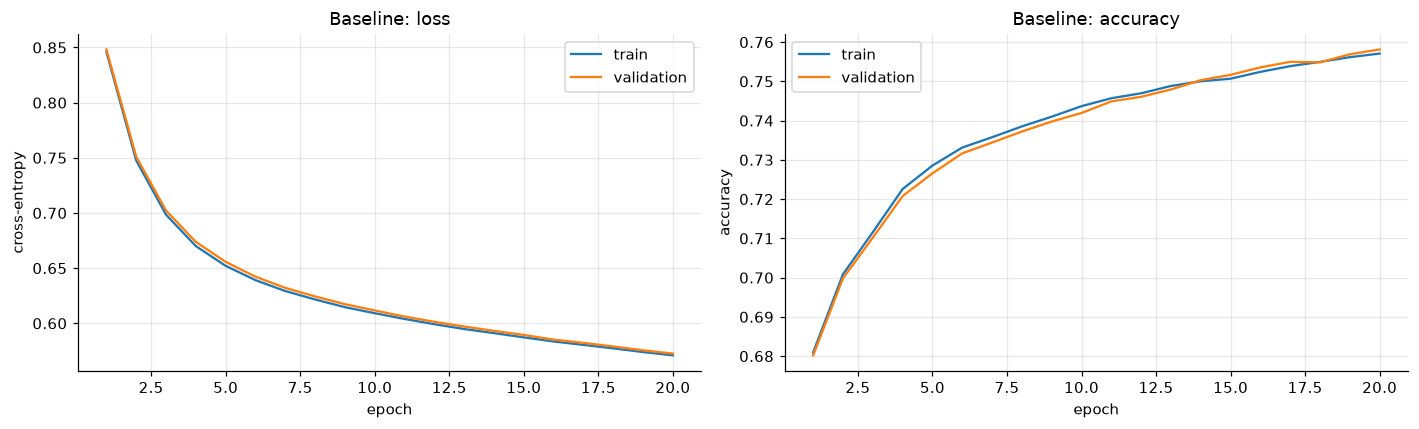

,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,roc_auc_ovr
train,0.7577,0.7252,0.4972,0.5181,0.7476,0.948
validation,0.7581,0.7191,0.4925,0.5122,0.7478,0.947


In [16]:
baseline_model, baseline_hist, baseline_info = train_model(BASE_CONFIG, DATA, verbose=True, run_name="baseline")
plot_history(baseline_hist, "Baseline", "figures/baseline_curves.png")

baseline_val = evaluate(baseline_model, X_val, y_val)
baseline_train = evaluate(baseline_model, X_train, y_train)
pd.DataFrame({"train": baseline_train, "validation": baseline_val}).T.round(4)

### Baseline observations
The baseline obtains training accuracy 75.77% / macro F1 0.5181 and validation accuracy 75.81% /
macro F1 0.5122. Its training and validation losses are close (0.5710 and 0.5726), with essentially no
accuracy gap. This is consistent with underfitting at this architecture, optimizer, and 20-epoch budget,
rather than severe overfitting. The much lower macro F1 than accuracy shows weak minority-class coverage.
These validation results motivate testing optimizers, activation functions and capacity before adding
regularization. The test set is not consulted to choose the next experiment.

## 6. Fine-tuning experiments

### 6.1 Method: controlled groups and explicit configuration comparisons
Each candidate starts from the same reference within its group, with every changed configuration key
recorded in the comparison table. Many comparisons isolate one setting; some deliberately compare a
bundle: optimizer plus a suitable learning rate (A), AdamW plus weight decay (A), one-cycle plus its
maximum learning rate (E), and BatchNorm plus Dropout (G). These bundled results do not isolate the causal
effect of a single technique. Architecture candidates also change width/depth together.
The split and random seed are fixed. Matching architecture/initialization gives matching initial weights,
but changes to architecture, initialization, batch size or Dropout can change random-number consumption
and subsequent shuffling. Equal seeds improve comparability; they do not guarantee identical batch order.

After each group, the configuration with the best **validation macro F1** becomes the reference for the next
group, but only if it beats the current reference; otherwise the reference stays unchanged. This greedy
coordinate search does not try every combination (that would be thousands of runs), but each decision is
backed by a direct comparison. The test set is never used here.

| Group | What is changed | Why |
|---|---|---|
| A Optimizer | SGD+momentum, RMSprop, Adam, AdamW | plain SGD is slow; adaptive methods usually converge faster |
| B Activation | tanh, LeakyReLU, ELU, GELU vs ReLU | effect of the non-linearity on gradient flow |
| C Architecture | wider and deeper hidden layers | the baseline may be too small (underfitting) |
| D Initialisation | Xavier, small normal, PyTorch default vs He | effect of the starting weights |
| E Learning rate | higher/lower lr, cosine, one-cycle, reduce-on-plateau | step size and annealing |
| F Batch size / epochs | 256, 1024, 2048; 10 and 40 epochs | gradient noise vs. speed; training length |
| G Regularisation | Dropout, L2, L1, BatchNorm | control overfitting as the network gets larger |
| H Class imbalance | balanced and square-root class weights | improve the rare classes |
| I Early stopping | 60 epochs with vs. without early stopping | final training length and overfitting control |

Each group's runs execute in separate worker processes (one CPU thread per worker). Runtime depends on
hardware and concurrent load. Numerical reproducibility across library versions/hardware is not guaranteed.
All conclusions below describe the committed seed-42 run; plausible mechanisms are interpretations, not
proof of causality. Repeated seeds would be needed to establish whether small differences are robust.

In [17]:
N_JOBS = max(1, min(4, (os.cpu_count() or 2) - 2))   # parallel training processes (one CPU core each)
RESULTS, HISTORIES, CONFIGS = [], {}, {}


def describe(changes):
    """Short text description of the changed hyper-parameters."""
    return ", ".join(f"{k}={v}" for k, v in changes.items()) if changes else "-"


CACHE_DIR = "results/cache"   # finished experiments are stored here; re-running the notebook reuses them
USE_CACHE = True              # set to False to retrain every experiment from scratch
os.makedirs(CACHE_DIR, exist_ok=True)


def load_cached_experiment(name, cfg):
    """Return a matching cached result, or None when this configuration needs training."""
    cache_path = os.path.join(CACHE_DIR, f"{name}.pt")
    if USE_CACHE and os.path.exists(cache_path):
        saved = torch.load(cache_path, weights_only=False)
        if saved["cfg"] == cfg:
            return saved["row"], saved["hist"], saved["cfg"], saved["state"]
    return None


def run_experiment(name, group, changes, base_cfg, data):
    """Train one configuration and collect metrics, reusing a matching cache when available."""
    cfg = {**base_cfg, **changes}
    cached = load_cached_experiment(name, cfg)
    if cached is not None:
        return cached
    cache_path = os.path.join(CACHE_DIR, f"{name}.pt")

    model, hist, info = train_model(cfg, data, run_name=name)
    tr = evaluate(model, data["X_train"], data["y_train"])
    va = evaluate(model, data["X_val"], data["y_val"])
    row = dict(exp=name, group=group, change=describe(changes), hidden=str(cfg["hidden"]),
               activation=cfg["activation"], init=cfg["init"], optimizer=cfg["optimizer"], lr=cfg["lr"],
               scheduler=cfg["scheduler"], batch_size=cfg["batch_size"], dropout=cfg["dropout"],
               batch_norm=cfg["batch_norm"], weight_decay=cfg["weight_decay"], l1=cfg["l1"],
               class_weight=cfg["class_weight"], early_stopping=cfg["early_stopping"], **info,
               train_loss=hist["train_loss"][-1], val_loss=hist["val_loss"][-1],
               train_acc=tr["accuracy"], train_f1_macro=tr["f1_macro"],
               val_acc=va["accuracy"], val_precision_macro=va["precision_macro"],
               val_recall_macro=va["recall_macro"], val_f1_macro=va["f1_macro"],
               val_f1_weighted=va["f1_weighted"], val_roc_auc=va["roc_auc_ovr"])
    row["overfit_gap_acc"] = row["train_acc"] - row["val_acc"]
    state = {k: v.cpu() for k, v in model.state_dict().items()}
    torch.save(dict(row=row, hist=hist, cfg=cfg, state=state), cache_path)
    return row, hist, cfg, state


def run_candidates(group, candidates, base_cfg, n_jobs):
    """Load caches in the parent; dispatch only unfinished experiments to worker processes."""
    completed, pending = {}, []
    for name, changes in candidates:
        cached = load_cached_experiment(name, {**base_cfg, **changes})
        if cached is None:
            pending.append((name, changes))
        else:
            completed[name] = cached
    if pending:
        # Disable automatic memmapping to avoid Windows resource-tracker cleanup errors.
        # Each worker gets its own data copy; reduce N_JOBS when memory is limited.
        trained = Parallel(n_jobs=n_jobs, backend="loky", max_nbytes=None)(
            delayed(run_experiment)(name, group, changes, base_cfg, DATA) for name, changes in pending)
        completed.update((name, output) for (name, _), output in zip(pending, trained))
    return [completed[name] for name, _ in candidates]


SHOW_COLS = ["exp", "change", "epochs_run", "train_time_s", "train_acc", "val_acc",
             "val_precision_macro", "val_recall_macro", "val_f1_macro", "val_roc_auc", "overfit_gap_acc"]


def run_group(group, candidates, ref_cfg, ref_name):
    """Run all candidates of a group in parallel, show a comparison, and return the new reference."""
    t0 = time.time()
    outs = run_candidates(group, candidates, ref_cfg, N_JOBS)
    for row, hist, cfg, _ in outs:
        RESULTS.append(row); HISTORIES[row["exp"]] = hist; CONFIGS[row["exp"]] = cfg

    ref_row = next(r for r in RESULTS if r["exp"] == ref_name)
    table = pd.DataFrame([ref_row] + [o[0] for o in outs])[SHOW_COLS]
    table.insert(1, "role", ["reference"] + ["candidate"] * len(outs))
    display(table.round(4))

    best_row = max([ref_row] + [o[0] for o in outs], key=lambda r: r["val_f1_macro"])
    new_name = best_row["exp"]
    print(f"Group {group} finished in {time.time() - t0:.0f}s -> reference is now '{new_name}' "
          f"(val macro F1 {best_row['val_f1_macro']:.4f}, val acc {best_row['val_acc']:.4f})")

    # Validation curves of every run in the group
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
    for name in [ref_name] + [n for n, _ in candidates]:
        h = HISTORIES[name]; ls = "--" if name == ref_name else "-"
        axes[0].plot(range(1, len(h["val_loss"]) + 1), h["val_loss"], ls, label=name)
        axes[1].plot(range(1, len(h["val_f1"]) + 1), h["val_f1"], ls, label=name)
    axes[0].set_title(f"Group {group}: validation loss"); axes[1].set_title(f"Group {group}: validation macro F1")
    for ax in axes:
        ax.set_xlabel("epoch"); ax.legend(fontsize=8)
    plt.tight_layout(); plt.savefig(f"figures/group_{group[0]}.png"); plt.show()
    return CONFIGS[new_name], new_name


# The baseline is the first entry of the experiment table
row, hist, cfg, _ = run_experiment("E00_baseline", "0 Baseline", {}, BASE_CONFIG, DATA)
RESULTS.append(row); HISTORIES[row["exp"]] = hist; CONFIGS[row["exp"]] = cfg
ref_cfg, ref_name = BASE_CONFIG, "E00_baseline"
print("Parallel workers:", N_JOBS)

Parallel workers: 4


### 6.2 Group A: optimizer
Plain SGD uses the same small step for every weight. Momentum smooths the updates; RMSprop and Adam adapt the
step size per parameter; AdamW additionally applies weight decay separately from the gradient step.

,exp,role,change,epochs_run,train_time_s,train_acc,val_acc,val_precision_macro,val_recall_macro,val_f1_macro,val_roc_auc,overfit_gap_acc
0,E00_baseline,reference,-,20,43.8,0.7577,0.7581,0.7191,0.4925,0.5122,0.9470,-0.0004
1,A1_sgd_momentum,candidate,"optimizer=sgd, momentum=0.9",20,47.6,0.8400,0.8372,0.7909,0.6372,0.6843,0.9770,0.0027
2,A2_rmsprop,candidate,"optimizer=rmsprop, lr=0.001",20,51.1,0.8479,0.8436,0.8149,0.6997,0.7393,0.9791,0.0043
3,A3_adam,candidate,"optimizer=adam, lr=0.001",20,56.1,0.8502,0.8453,0.8121,0.7040,0.7447,0.9797,0.0049
4,A4_adamw,candidate,"optimizer=adamw, lr=0.001, weight_decay=0.0001",20,57.4,0.8494,0.8446,0.8103,0.7042,0.7438,0.9798,0.0049


Group A Optimizer finished in 0s -> reference is now 'A3_adam' (val macro F1 0.7447, val acc 0.8453)


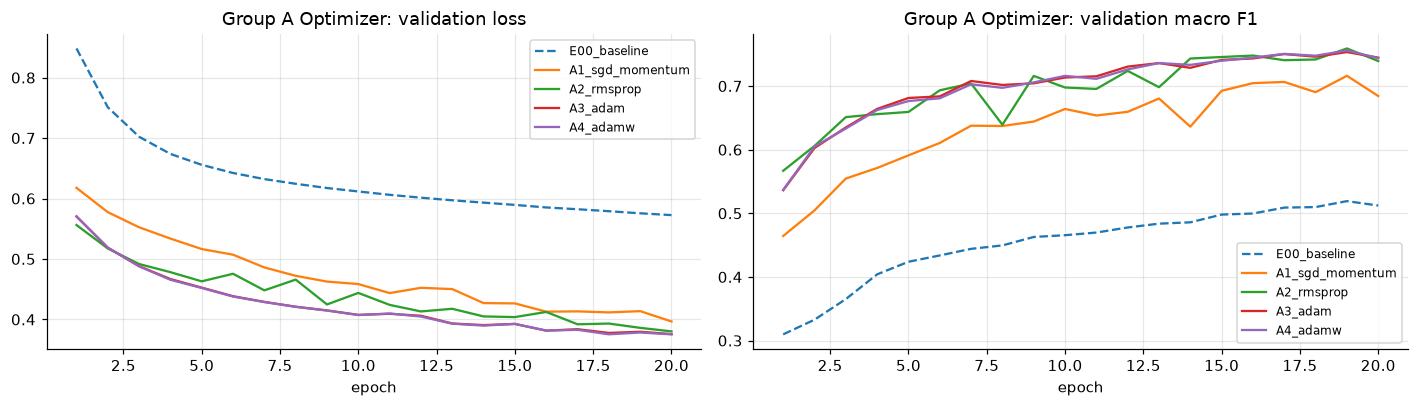

In [18]:
ref_cfg, ref_name = run_group("A Optimizer", [
    ("A1_sgd_momentum", dict(optimizer="sgd", momentum=0.9)),
    ("A2_rmsprop", dict(optimizer="rmsprop", lr=1e-3)),
    ("A3_adam", dict(optimizer="adam", lr=1e-3)),
    ("A4_adamw", dict(optimizer="adamw", lr=1e-3, weight_decay=1e-4)),
], ref_cfg, ref_name)

**Group A observations.** Validation macro F1 improves from 0.5122 (plain SGD) to 0.6843 with momentum,
0.7393 with RMSprop, 0.7447 with Adam, and 0.7438 with AdamW. Adam at 0.001 becomes the next reference.
Adaptive updates plausibly help this network converge faster within 20 epochs. The optimizer/learning-rate
bundles are being compared, so the gain cannot be attributed to the optimizer alone. AdamW's additional
weight decay does not improve this run, and its 0.0009 F1 difference from Adam is too small for a general claim.

### 6.3 Group B: activation function

,exp,role,change,epochs_run,train_time_s,train_acc,val_acc,val_precision_macro,val_recall_macro,val_f1_macro,val_roc_auc,overfit_gap_acc
0,A3_adam,reference,"optimizer=adam, lr=0.001",20,56.1,0.8502,0.8453,0.8121,0.7040,0.7447,0.9797,0.0049
1,B1_tanh,candidate,activation=tanh,20,56.3,0.8616,0.8561,0.8223,0.7344,0.7693,0.9820,0.0055
2,B2_leaky_relu,candidate,activation=leaky_relu,20,52.6,0.8494,0.8448,0.8089,0.6980,0.7398,0.9796,0.0047
3,B3_elu,candidate,activation=elu,20,60.4,0.8307,0.8288,0.7944,0.6628,0.7077,0.9753,0.0020
4,B4_gelu,candidate,activation=gelu,20,62.1,0.8540,0.8508,0.8173,0.7283,0.7633,0.9808,0.0032


Group B Activation finished in 0s -> reference is now 'B1_tanh' (val macro F1 0.7693, val acc 0.8561)


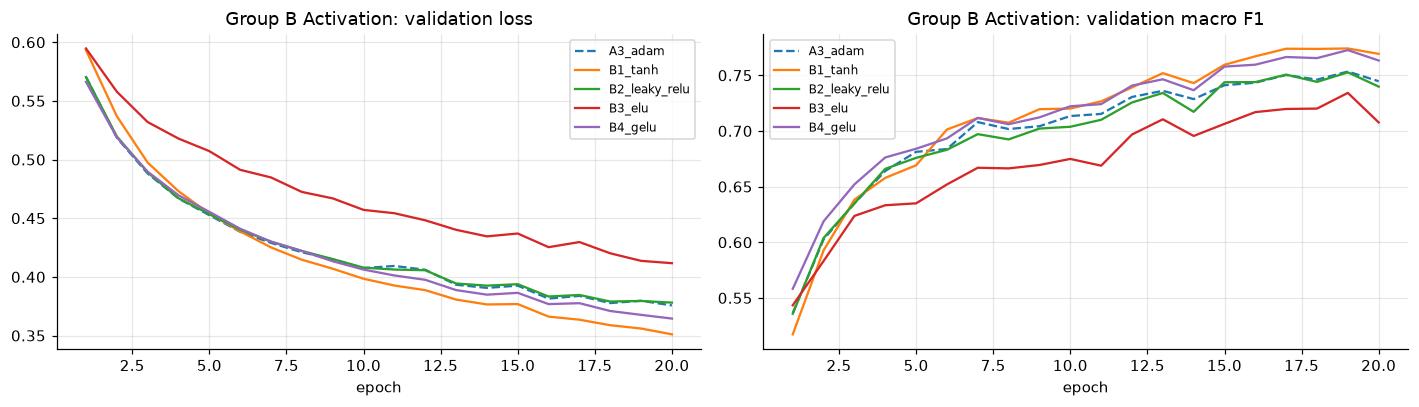

In [19]:
ref_cfg, ref_name = run_group("B Activation", [
    ("B1_tanh", dict(activation="tanh")),
    ("B2_leaky_relu", dict(activation="leaky_relu")),
    ("B3_elu", dict(activation="elu")),
    ("B4_gelu", dict(activation="gelu")),
], ref_cfg, ref_name)

**Group B observations.** Tanh gives validation macro F1 0.7693 versus ReLU's 0.7447, GELU's 0.7633,
LeakyReLU's 0.7398 and ELU's 0.7077. Tanh is selected for the next group. Its bounded, zero-centered output
may suit these standardized tabular inputs, but this result is conditional on the small architecture,
He initialization and optimizer used here. It does not establish that tanh is universally best.

### 6.4 Group C: number of hidden layers and neurons

,exp,role,change,epochs_run,train_time_s,train_acc,val_acc,val_precision_macro,val_recall_macro,val_f1_macro,val_roc_auc,overfit_gap_acc
0,B1_tanh,reference,activation=tanh,20,56.3,0.8616,0.8561,0.8223,0.7344,0.7693,0.9820,0.0055
1,C1_128-64,candidate,"hidden=(128, 64)",20,71.6,0.9020,0.8948,0.8616,0.8182,0.8378,0.9897,0.0072
2,C2_256-128,candidate,"hidden=(256, 128)",20,120.6,0.9298,0.9200,0.8869,0.8690,0.8773,0.9939,0.0097
3,C3_128-64-32,candidate,"hidden=(128, 64, 32)",20,79.8,0.9121,0.9045,0.8686,0.8306,0.8471,0.9916,0.0076
4,C4_256-128-64,candidate,"hidden=(256, 128, 64)",20,149.4,0.9392,0.9279,0.8925,0.8727,0.8811,0.9951,0.0113


Group C Architecture finished in 0s -> reference is now 'C4_256-128-64' (val macro F1 0.8811, val acc 0.9279)


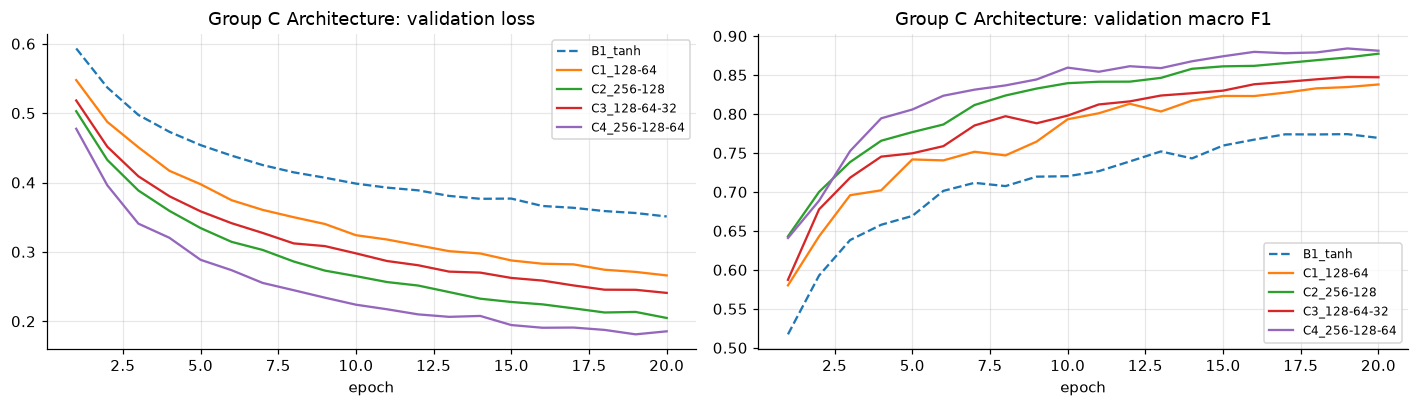

In [20]:
ref_cfg, ref_name = run_group("C Architecture", [
    ("C1_128-64", dict(hidden=(128, 64))),
    ("C2_256-128", dict(hidden=(256, 128))),
    ("C3_128-64-32", dict(hidden=(128, 64, 32))),
    ("C4_256-128-64", dict(hidden=(256, 128, 64))),
], ref_cfg, ref_name)

**Group C observations.** Validation macro F1 rises to 0.8378 for (128, 64), 0.8773 for (256, 128),
0.8471 for (128, 64, 32), and 0.8811 for (256, 128, 64). The last architecture is selected.
The gains support the baseline-underfitting diagnosis: additional capacity captures relationships that
the small network misses. Its training/validation accuracy gap grows to 1.13 percentage points, so capacity
also increases overfitting risk. Width and depth interact; these candidates are architecture comparisons.

### 6.5 Group D: weight initialisation

,exp,role,change,epochs_run,train_time_s,train_acc,val_acc,val_precision_macro,val_recall_macro,val_f1_macro,val_roc_auc,overfit_gap_acc
0,C4_256-128-64,reference,"hidden=(256, 128, 64)",20,149.4,0.9392,0.9279,0.8925,0.8727,0.8811,0.9951,0.0113
1,D1_xavier,candidate,init=xavier,20,264.2,0.9351,0.9251,0.8949,0.8724,0.8824,0.9950,0.0100
2,D2_normal_0.01,candidate,init=normal,20,265.4,0.9254,0.9167,0.8923,0.8512,0.8690,0.9939,0.0087
3,D3_pytorch_default,candidate,init=default,20,265.4,0.9335,0.9234,0.8961,0.8610,0.8764,0.9948,0.0101


Group D Initialisation finished in 0s -> reference is now 'D1_xavier' (val macro F1 0.8824, val acc 0.9251)


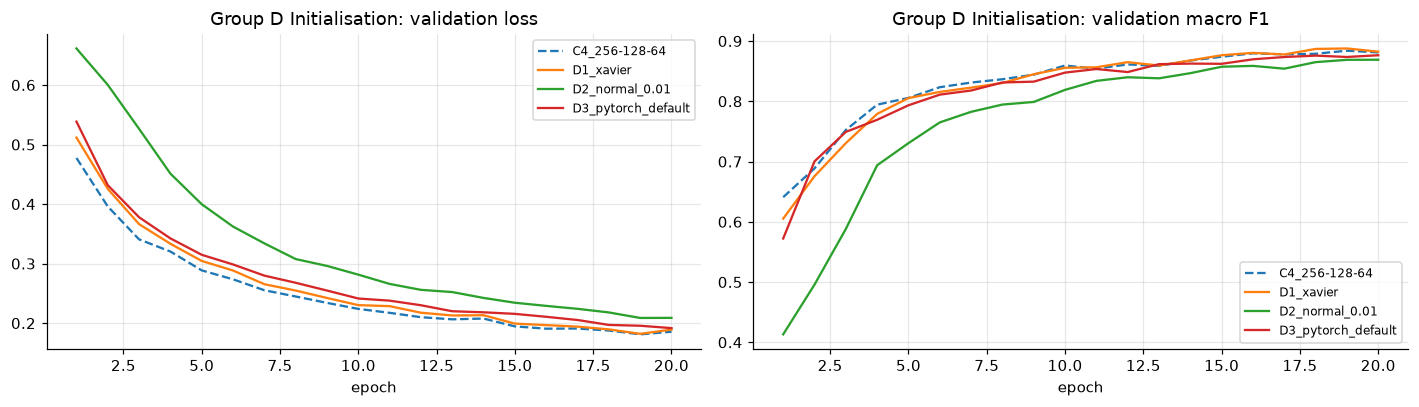

In [21]:
ref_cfg, ref_name = run_group("D Initialisation", [
    ("D1_xavier", dict(init="xavier")),
    ("D2_normal_0.01", dict(init="normal")),
    ("D3_pytorch_default", dict(init="default")),
], ref_cfg, ref_name)

**Group D observations.** Xavier reaches validation macro F1 0.8824 versus He's 0.8811, PyTorch default's
0.8764 and small-normal initialization's 0.8690. Xavier becomes the reference under the predefined F1 rule,
even though its validation accuracy (92.51%) is below He's (92.79%). This illustrates why selection follows
macro F1 rather than accuracy. Xavier is a natural match for tanh, but the 0.0013 gain over He needs
confirmation across seeds; the initialization result is not statistically established by this single run.

### 6.6 Group E: learning rate and learning-rate schedules

,exp,role,change,epochs_run,train_time_s,train_acc,val_acc,val_precision_macro,val_recall_macro,val_f1_macro,val_roc_auc,overfit_gap_acc
0,D1_xavier,reference,init=xavier,20,264.2,0.9351,0.9251,0.8949,0.8724,0.8824,0.9950,0.0100
1,E1_lr_3e-3,candidate,lr=0.003,20,150.3,0.9374,0.9243,0.8812,0.8735,0.8767,0.9949,0.0131
2,E2_lr_3e-4,candidate,lr=0.0003,20,149.9,0.9007,0.8950,0.8607,0.7981,0.8253,0.9898,0.0056
3,E3_cosine,candidate,scheduler=cosine,20,150.5,0.9289,0.9207,0.8954,0.8565,0.8745,0.9939,0.0082
4,E4_onecycle_3e-3,candidate,"scheduler=onecycle, lr=0.003",20,151.2,0.9558,0.9417,0.9133,0.8890,0.9005,0.9965,0.0140
5,E5_plateau,candidate,scheduler=plateau,20,120.1,0.9351,0.9251,0.8949,0.8724,0.8824,0.9950,0.0100


Group E Learning rate finished in 0s -> reference is now 'E4_onecycle_3e-3' (val macro F1 0.9005, val acc 0.9417)


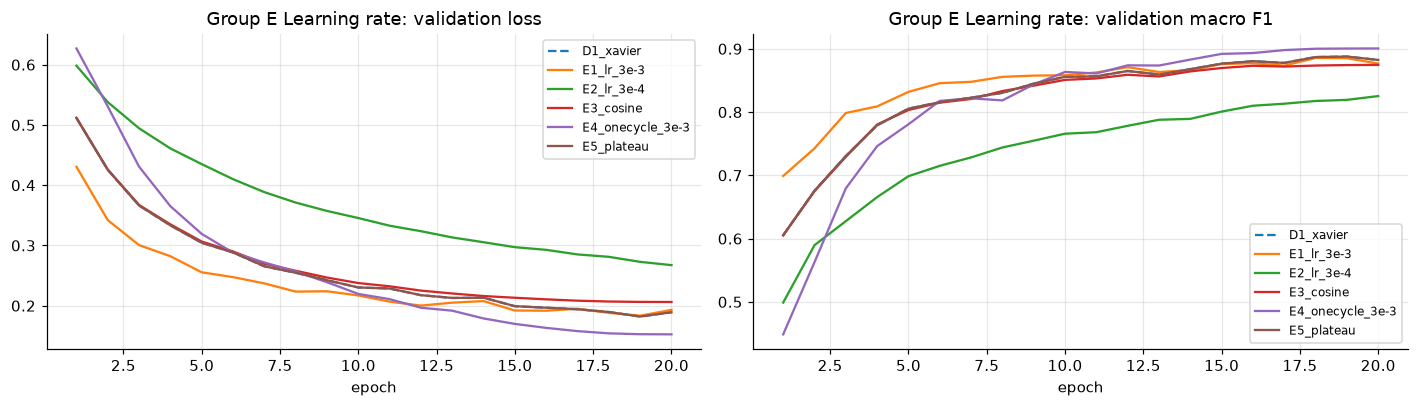

In [22]:
ref_cfg, ref_name = run_group("E Learning rate", [
    ("E1_lr_3e-3", dict(lr=3e-3)),
    ("E2_lr_3e-4", dict(lr=3e-4)),
    ("E3_cosine", dict(scheduler="cosine")),
    ("E4_onecycle_3e-3", dict(scheduler="onecycle", lr=3e-3)),
    ("E5_plateau", dict(scheduler="plateau")),
], ref_cfg, ref_name)

**Group E observations.** One-cycle with maximum learning rate 0.003 achieves validation macro F1 0.9005,
ahead of the 0.001 constant-rate reference (0.8824), constant 0.003 (0.8767), constant 0.0003 (0.8253),
and cosine (0.8745). Plateau matches the reference (0.8824); its logged behavior provides no improvement
at this budget. The one-cycle/rate bundle is selected. Warming up and annealing plausibly improves the
optimization trajectory; comparing it directly with constant 0.003 also supports a scheduling benefit.

### 6.7 Group F: batch size and number of epochs

,exp,role,change,epochs_run,train_time_s,train_acc,val_acc,val_precision_macro,val_recall_macro,val_f1_macro,val_roc_auc,overfit_gap_acc
0,E4_onecycle_3e-3,reference,"scheduler=onecycle, lr=0.003",20,151.2,0.9558,0.9417,0.9133,0.8890,0.9005,0.9965,0.0140
1,F1_bs_256,candidate,batch_size=256,20,210.6,0.9614,0.9449,0.9199,0.8980,0.9085,0.9969,0.0165
2,F2_bs_1024,candidate,batch_size=1024,20,130.3,0.9452,0.9339,0.9077,0.8770,0.8913,0.9957,0.0113
3,F3_bs_2048,candidate,batch_size=2048,20,118.2,0.9288,0.9194,0.8938,0.8540,0.8723,0.9938,0.0093
4,F4_epochs_10,candidate,epochs=10,10,78.2,0.9338,0.9235,0.8980,0.8578,0.8764,0.9944,0.0103
5,F5_epochs_40,candidate,epochs=40,40,273.7,0.9729,0.9521,0.9292,0.9145,0.9216,0.9975,0.0208


Group F Batch size & epochs finished in 0s -> reference is now 'F5_epochs_40' (val macro F1 0.9216, val acc 0.9521)


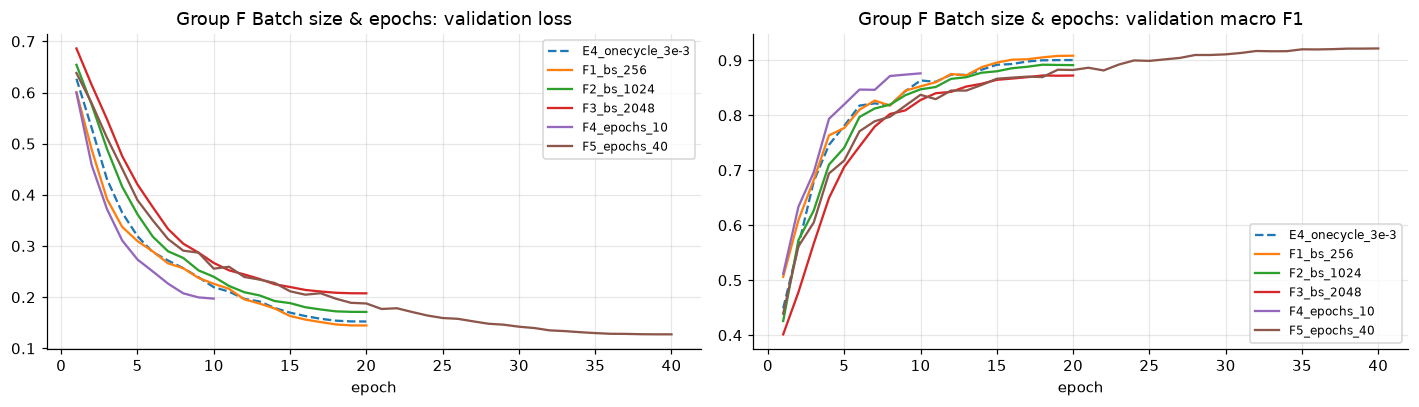

In [23]:
ref_cfg, ref_name = run_group("F Batch size & epochs", [
    ("F1_bs_256", dict(batch_size=256)),
    ("F2_bs_1024", dict(batch_size=1024)),
    ("F3_bs_2048", dict(batch_size=2048)),
    ("F4_epochs_10", dict(epochs=10)),
    ("F5_epochs_40", dict(epochs=40)),
], ref_cfg, ref_name)

**Group F observations.** At 20 epochs, batch 256 gives validation macro F1 0.9085, versus batch 512's
0.9005, batch 1024's 0.8913 and batch 2048's 0.8723. Smaller batches make more gradient updates per epoch,
so these are comparisons at fixed passes through the data, not equal optimizer-step budgets.
Training for 10 epochs gives 0.8764; 40 epochs at batch 512 gives the group's best F1, 0.9216.
The 40-epoch configuration becomes the reference. With one-cycle, changing epochs also stretches the
learning-rate schedule. Its 2.08-point train/validation accuracy gap motivates regularization tests.

### 6.8 Group G: regularisation (Dropout, L2, L1, Batch Normalisation)
* **Dropout** randomly switches off a share of neurons in each training step, so the network cannot rely on
  a few co-adapted neurons.
* **L2 / weight decay** adds `lambda * sum(w^2)` (or decays weights directly in AdamW), keeping weights small.
* **L1** adds `lambda * sum(|w|)`, which pushes unimportant weights to exactly zero.
* **Batch Normalisation** normalises each hidden layer's pre-activations over the mini-batch; it stabilises and
  often speeds up training and has a mild regularising effect.

,exp,role,change,epochs_run,train_time_s,train_acc,val_acc,val_precision_macro,val_recall_macro,val_f1_macro,val_roc_auc,overfit_gap_acc
0,F5_epochs_40,reference,epochs=40,40,273.7,0.9729,0.9521,0.9292,0.9145,0.9216,0.9975,0.0208
1,G1_dropout_0.1,candidate,dropout=0.1,40,401.6,0.9239,0.9164,0.8861,0.8635,0.8742,0.9935,0.0075
2,G2_dropout_0.3,candidate,dropout=0.3,40,402.6,0.8642,0.8612,0.8320,0.7682,0.7941,0.9833,0.0029
3,G3_l2_1e-3,candidate,weight_decay=0.001,40,265.1,0.8676,0.8646,0.8214,0.7024,0.7448,0.9835,0.0031
4,G4_l1_1e-5,candidate,l1=1e-05,40,282.1,0.9638,0.9492,0.9284,0.9057,0.9165,0.9974,0.0146
5,G5_batchnorm,candidate,batch_norm=True,40,301.6,0.9742,0.9559,0.9368,0.9224,0.9294,0.9979,0.0183
6,G6_batchnorm_dropout_0.1,candidate,"batch_norm=True, dropout=0.1",40,430.2,0.9409,0.9311,0.9040,0.8905,0.8970,0.9955,0.0098


Group G Regularisation finished in 0s -> reference is now 'G5_batchnorm' (val macro F1 0.9294, val acc 0.9559)


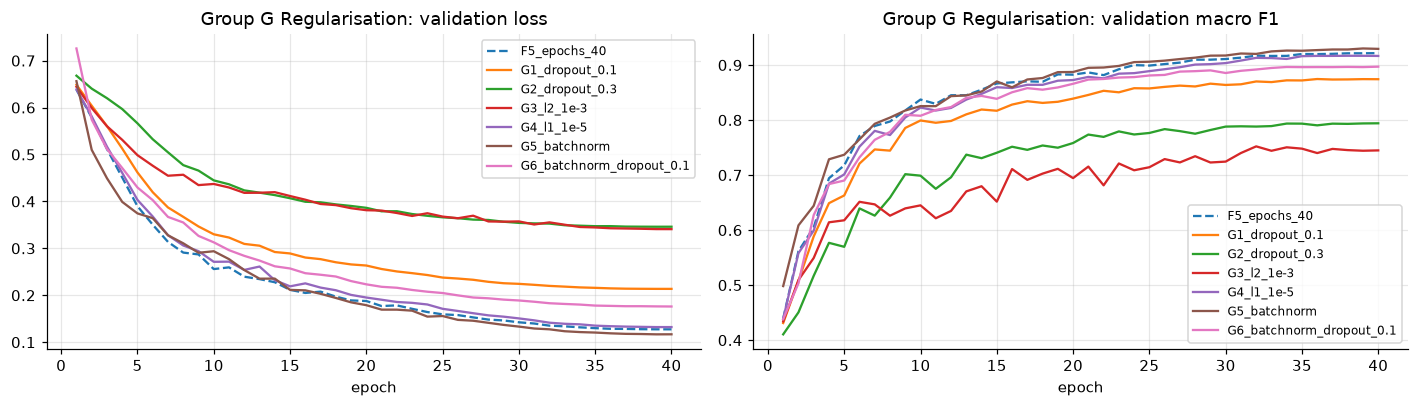

In [24]:
ref_cfg, ref_name = run_group("G Regularisation", [
    ("G1_dropout_0.1", dict(dropout=0.1)),
    ("G2_dropout_0.3", dict(dropout=0.3)),
    ("G3_l2_1e-3", dict(weight_decay=1e-3)),
    ("G4_l1_1e-5", dict(l1=1e-5)),
    ("G5_batchnorm", dict(batch_norm=True)),
    ("G6_batchnorm_dropout_0.1", dict(batch_norm=True, dropout=0.1)),
], ref_cfg, ref_name)

**Group G observations.** BatchNorm improves validation macro F1 from 0.9216 to 0.9294 and reduces the
accuracy gap from 2.08 to 1.83 percentage points. It becomes the reference. Dropout 0.1/0.3 scores
0.8742/0.7941; L2 at 0.001 scores 0.7448; L1 at 0.00001 scores 0.9165; BatchNorm plus Dropout 0.1 scores
0.8970. Stronger regularization narrows gaps but can underfit: a smaller gap alone is not success.
At these tested strengths it reduces validation performance. BatchNorm's normalization may stabilize
optimization. The combination candidate changes two settings relative to the no-BatchNorm reference.

### 6.9 Group H: class-imbalance handling

,exp,role,change,epochs_run,train_time_s,train_acc,val_acc,val_precision_macro,val_recall_macro,val_f1_macro,val_roc_auc,overfit_gap_acc
0,G5_batchnorm,reference,batch_norm=True,40,301.6,0.9742,0.9559,0.9368,0.9224,0.9294,0.9979,0.0183
1,H1_balanced_weights,candidate,class_weight=balanced,40,290.2,0.9423,0.9301,0.8597,0.9537,0.9006,0.9960,0.0122
2,H2_sqrt_weights,candidate,class_weight=sqrt,40,289.7,0.9677,0.9503,0.9083,0.9478,0.9268,0.9977,0.0174


Group H Class imbalance finished in 0s -> reference is now 'G5_batchnorm' (val macro F1 0.9294, val acc 0.9559)


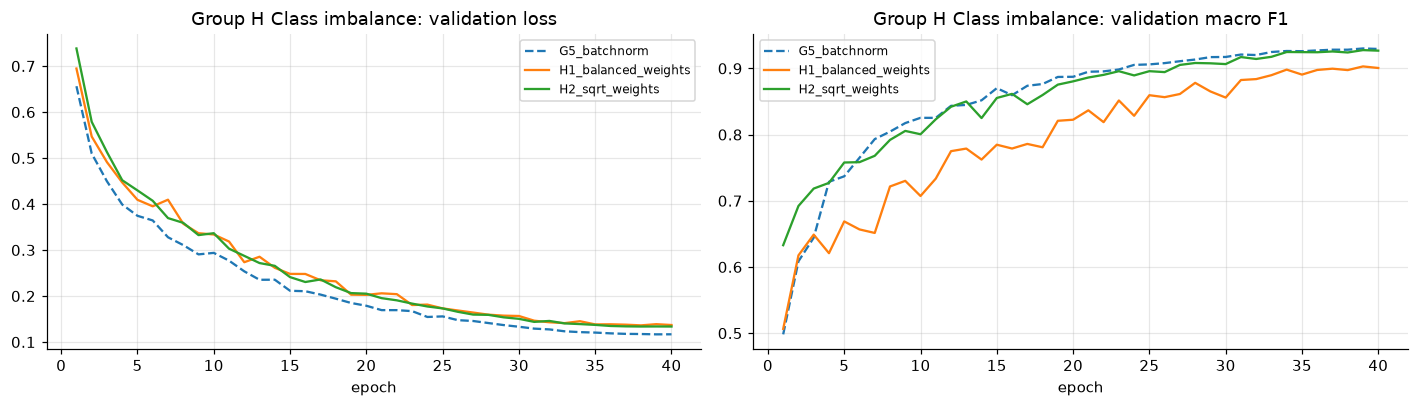

In [25]:
ref_cfg, ref_name = run_group("H Class imbalance", [
    ("H1_balanced_weights", dict(class_weight="balanced")),
    ("H2_sqrt_weights", dict(class_weight="sqrt")),
], ref_cfg, ref_name)

**Group H observations.** Balanced weighting raises validation macro recall from 0.9224 to 0.9537, but
lowers macro precision from 0.9368 to 0.8597 and F1 from 0.9294 to 0.9006. Square-root weights produce
precision 0.9083, recall 0.9478 and F1 0.9268. Weighting trades more minority-class detections for false
positives. Neither beats the unweighted BatchNorm reference on the chosen macro F1 objective, so class
weights stay off. A recall-focused application could reasonably choose a different operating objective.

## 7. Final model: longer training with early stopping
The screening runs above used a fixed, short budget (20 epochs for most runs) so many configurations could be
compared fairly. The best configuration is now trained for up to **60 epochs**, once with a fixed number of
epochs and once with **early stopping** (patience 8 on the validation loss, restoring the best weights).
Both are candidates; validation macro F1 decides which is selected, including the option without early stopping.

In [26]:
print("Best configuration from the fine-tuning search:", ref_name)
for k, v in ref_cfg.items():
    print(f"  {k:15s}: {v}")

final_candidates = [
    ("I1_final_60ep_no_es", dict(epochs=60, early_stopping=False)),
    ("I2_final_60ep_early_stopping", dict(epochs=60, early_stopping=True, patience=8)),
]
outs = run_candidates("I Early stopping", final_candidates, ref_cfg, 2)
final_states = {}
for row, hist, cfg, state in outs:
    RESULTS.append(row); HISTORIES[row["exp"]] = hist; CONFIGS[row["exp"]] = cfg; final_states[row["exp"]] = state
display(pd.DataFrame([o[0] for o in outs])[SHOW_COLS + ["best_epoch"]].round(4))

Best configuration from the fine-tuning search: G5_batchnorm
  hidden         : (256, 128, 64)
  activation     : tanh
  init           : xavier
  dropout        : 0.0
  batch_norm     : True
  weight_decay   : 0.0
  l1             : 0.0
  optimizer      : adam
  lr             : 0.003
  momentum       : 0.0
  scheduler      : onecycle
  batch_size     : 512
  epochs         : 40
  class_weight   : None
  early_stopping : False
  patience       : 8


,exp,change,epochs_run,train_time_s,train_acc,val_acc,val_precision_macro,val_recall_macro,val_f1_macro,val_roc_auc,overfit_gap_acc,best_epoch
0,I1_final_60ep_no_es,"epochs=60, early_stopping=False",60,439.5,0.9802,0.9584,0.9367,0.9274,0.9320,0.9981,0.0218,59
1,I2_final_60ep_early_stopping,"epochs=60, early_stopping=True, patience=8",60,439.9,0.9802,0.9581,0.9383,0.9253,0.9317,0.9981,0.0221,59


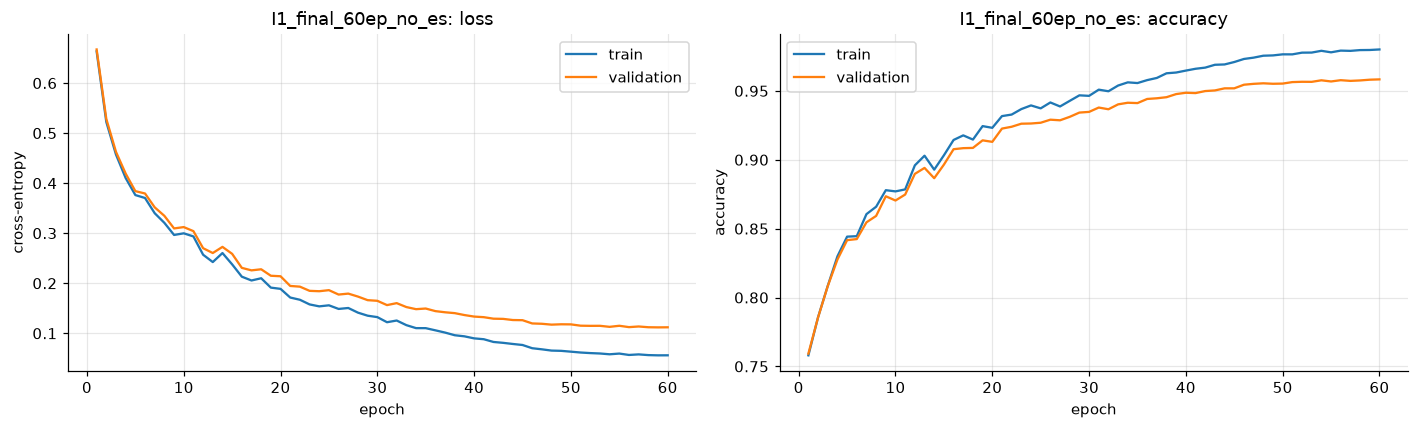

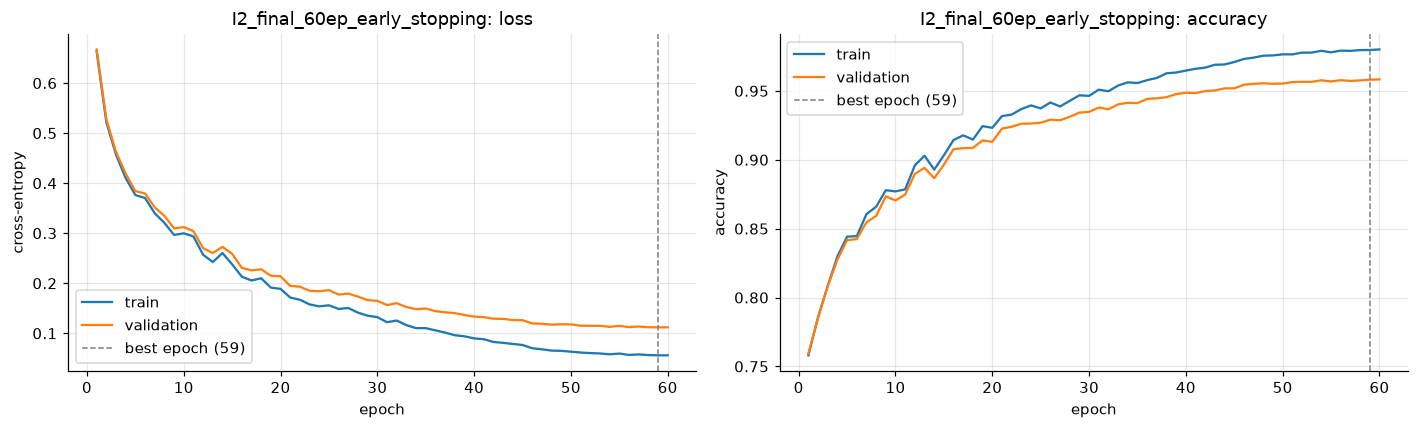

In [27]:
for name, _ in final_candidates:
    r = next(r for r in RESULTS if r["exp"] == name)
    plot_history(HISTORIES[name], name, f"figures/{name}_curves.png",
                 best_epoch=r["best_epoch"] if r["early_stopping"] else None)

**Group I observations.** Both candidates run all 60 epochs: patience 8 is never exhausted, so early stopping
does not save training time in this run. The lowest validation loss is recorded at epoch 59; the enabled
candidate restores that checkpoint. The fixed-length candidate retains epoch 60, obtaining validation macro
F1 0.931955 versus 0.931673 for the restored candidate. It is selected because F1, rather than minimum loss,
is the model-selection objective. The difference is small and does not show that early stopping is harmful.
These curves show continued convergence with a modest generalization gap, not a demonstrated early-stop
reduction in overfitting. A larger epoch budget or repeated seeds could evaluate that question further.

### 7.1 Final model selection
The final model is the run with the highest validation macro F1 among *all* experiments (validation set only).
Its weights are saved together with the configuration and the preprocessing parameters, so it can be reused
for new data without retraining.

In [28]:
results_df = pd.DataFrame(RESULTS)
results_df.to_csv("results/experiments.csv", index=False)

FINAL_NAME = results_df.sort_values("val_f1_macro", ascending=False).iloc[0]["exp"]
FINAL_CFG = CONFIGS[FINAL_NAME]
if FINAL_NAME in final_states:            # weights already available from the final runs
    final_model = MLP(N_FEATURES, N_CLASSES, hidden=FINAL_CFG["hidden"], activation=FINAL_CFG["activation"],
                      dropout=FINAL_CFG["dropout"], batch_norm=FINAL_CFG["batch_norm"], init=FINAL_CFG["init"])
    final_model.load_state_dict(final_states[FINAL_NAME])
else:                                     # retrain (same seed -> same weights) if a screening run won
    final_model, _, _ = train_model(FINAL_CFG, DATA)
print("Selected final model:", FINAL_NAME)
print(final_model)
print("Trainable parameters:", sum(p.numel() for p in final_model.parameters()))

torch.save({"format_version": 2, "state_dict": final_model.state_dict(), "config": FINAL_CFG,
            "features": FEATURES, "cont_cols": CONT_COLS, "imputer_median": TRAIN_MEDIANS.tolist(),
            "scaler_mean": scaler.mean_.tolist(), "scaler_scale": scaler.scale_.tolist(),
            "clip_low": LOW.tolist(), "clip_high": HIGH.tolist(), "class_names": LABELS},
           "models/final_mlp.pt")
print("Saved to models/final_mlp.pt")

Selected final model: I1_final_60ep_no_es
MLP(
  (net): Sequential(
    (0): Linear(in_features=56, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): Tanh()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): Tanh()
    (6): Linear(in_features=128, out_features=64, bias=True)
    (7): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (8): Tanh()
    (9): Linear(in_features=64, out_features=7, bias=True)
  )
)
Trainable parameters: 57095
Saved to models/final_mlp.pt


## 8. Final evaluation on the held-out test set
The test set is used here **for the first and only time**, for the baseline and for the selected final
model. No decision was based on it.

**Why these metrics?** Accuracy is easy to interpret but is dominated by Spruce/Fir and Lodgepole Pine (85% of
the data); a model could ignore the rare classes and still score high. Macro precision, recall and F1 treat all
seven cover types equally, which matches the real-world goal of mapping *every* forest type, including the rare
riparian Cottonwood/Willow and Aspen stands. ROC-AUC measures how well the predicted probabilities rank the
correct class, independent of the decision threshold, and the confusion matrix shows exactly which species are
confused with each other.

In [29]:
final_scores = {split: evaluate(final_model, X, y) for split, X, y in
                [("train", X_train, y_train), ("validation", X_val, y_val), ("test", X_test, y_test)]}
base_scores = {split: evaluate(baseline_model, X, y) for split, X, y in
               [("train", X_train, y_train), ("validation", X_val, y_val), ("test", X_test, y_test)]}
comparison = pd.concat({"Baseline": pd.DataFrame(base_scores).T, "Final model": pd.DataFrame(final_scores).T})
comparison.to_csv("results/baseline_vs_final.csv")
comparison.round(4)

accuracy  precision_macro  recall_macro  f1_macro  f1_weighted  roc_auc_ovr
Baseline    train         0.7577           0.7252        0.4972    0.5181       0.7476       0.9480
            validation    0.7581           0.7191        0.4925    0.5122       0.7478       0.9470
            test          0.7590           0.7354        0.4971    0.5188       0.7490       0.9479
Final model train         0.9802           0.9715        0.9699    0.9707       0.9802       0.9996
            validation    0.9584           0.9367        0.9274    0.9320       0.9583       0.9981
            test          0.9592           0.9363        0.9298    0.9330       0.9592       0.9981

In [30]:
test_proba = torch.softmax(predict_logits(final_model, torch.as_tensor(X_test)), 1).numpy()
test_pred = test_proba.argmax(1)
base_test_pred = predict_logits(baseline_model, torch.as_tensor(X_test)).argmax(1).numpy()

print("FINAL MODEL - test set classification report")
print(classification_report(y_test, test_pred, target_names=LABELS, digits=4))

FINAL MODEL - test set classification report
                   precision    recall  f1-score   support

       Spruce/Fir     0.9597    0.9558    0.9577     31776
   Lodgepole Pine     0.9635    0.9678    0.9656     42496
   Ponderosa Pine     0.9571    0.9573    0.9572      5363
Cottonwood/Willow     0.8859    0.8665    0.8761       412
            Aspen     0.8992    0.8771    0.8880      1424
      Douglas-fir     0.9249    0.9225    0.9237      2605
        Krummholz     0.9635    0.9616    0.9626      3076

         accuracy                         0.9592     87152
        macro avg     0.9363    0.9298    0.9330     87152
     weighted avg     0.9592    0.9592    0.9592     87152



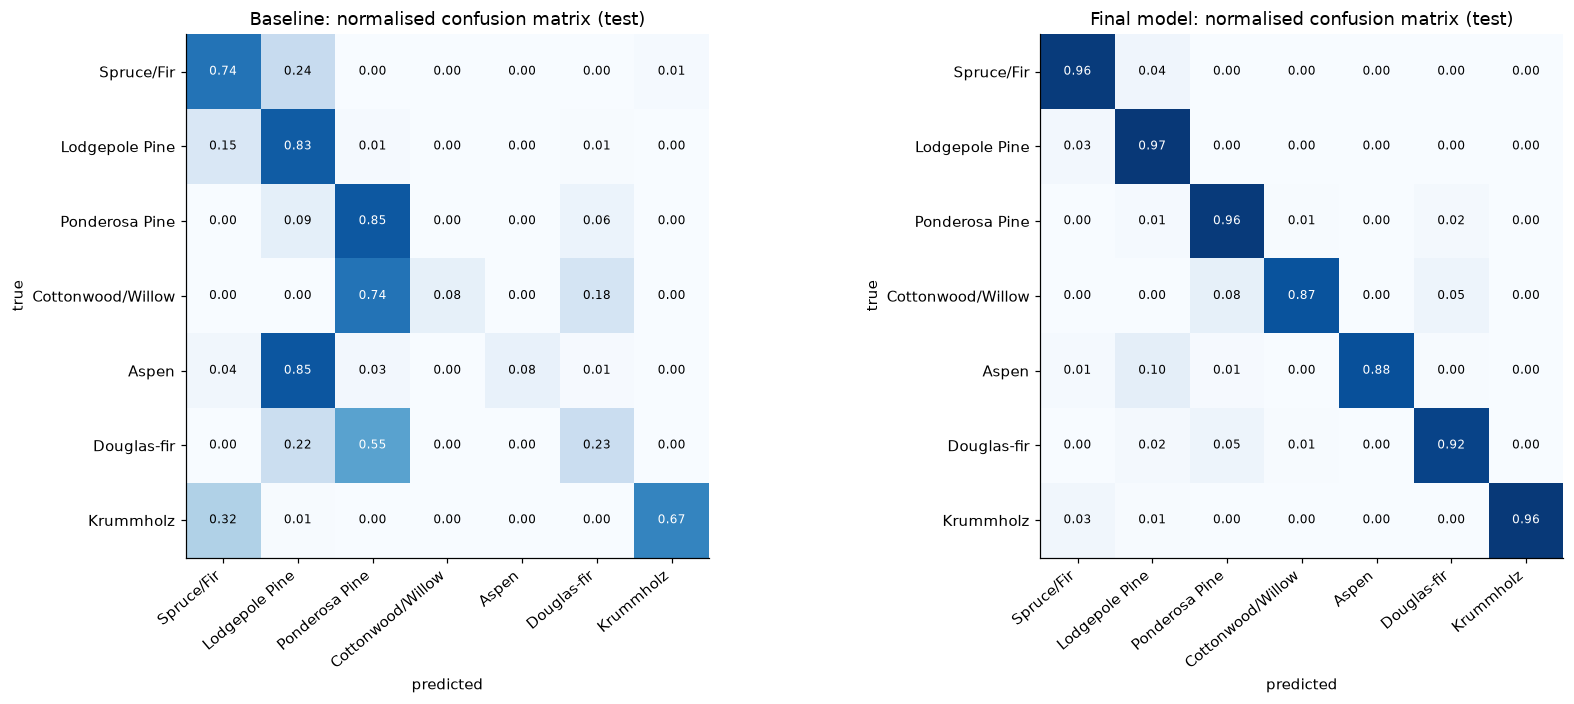

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, pred, title in [(axes[0], base_test_pred, "Baseline"), (axes[1], test_pred, "Final model")]:
    cm = confusion_matrix(y_test, pred, normalize="true")       # each row sums to 1 (= recall per class)
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(N_CLASSES):
        for j in range(N_CLASSES):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if cm[i, j] > 0.5 else "black")
    ax.set_xticks(range(N_CLASSES)); ax.set_xticklabels(LABELS, rotation=40, ha="right")
    ax.set_yticks(range(N_CLASSES)); ax.set_yticklabels(LABELS)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.grid(False)
    ax.set_title(f"{title}: normalised confusion matrix (test)")
plt.tight_layout(); plt.savefig("figures/test_confusion_matrices.png"); plt.show()

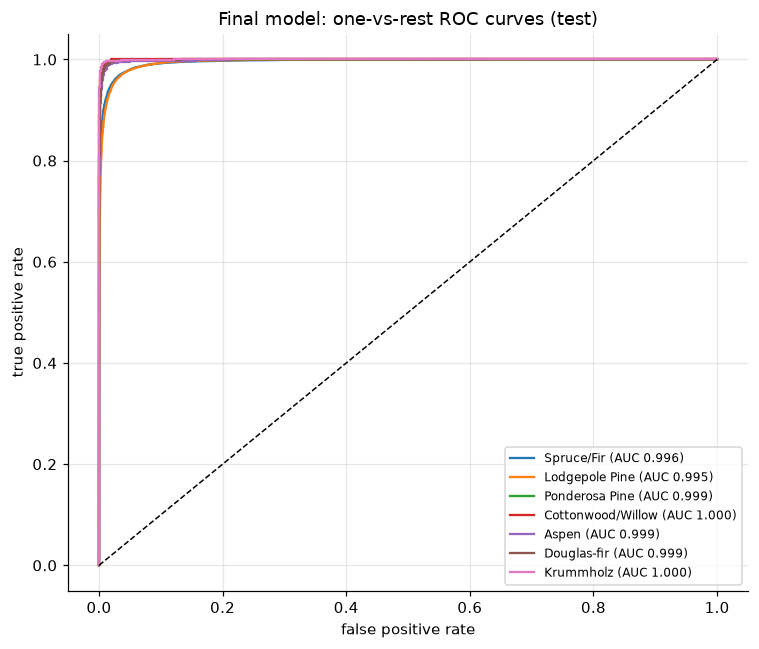

In [32]:
# One-vs-rest ROC curves of the final model on the test set
fig, ax = plt.subplots(figsize=(7, 6))
for k, name in enumerate(LABELS):
    fpr, tpr, _ = roc_curve(y_test == k, test_proba[:, k])
    ax.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test == k, test_proba[:, k]):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
ax.set_title("Final model: one-vs-rest ROC curves (test)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("figures/test_roc_curves.png"); plt.show()

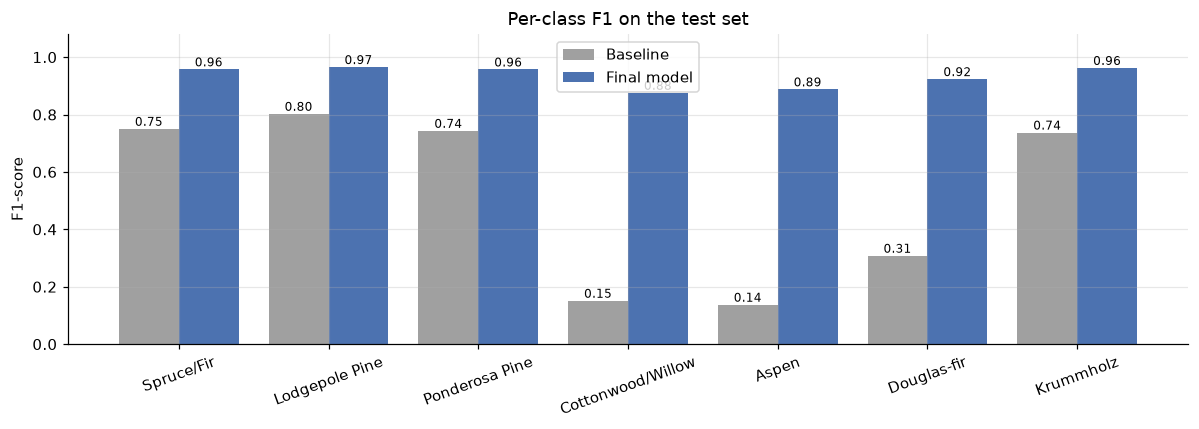

In [33]:
# Per-class F1: baseline vs final model on the test set
f1_base = f1_score(y_test, base_test_pred, average=None)
f1_final = f1_score(y_test, test_pred, average=None)
x = np.arange(N_CLASSES)
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(x - 0.2, f1_base, 0.4, label="Baseline", color="#A0A0A0")
ax.bar(x + 0.2, f1_final, 0.4, label="Final model", color="#4C72B0")
for i in x:
    ax.text(i - 0.2, f1_base[i] + 0.01, f"{f1_base[i]:.2f}", ha="center", fontsize=8)
    ax.text(i + 0.2, f1_final[i] + 0.01, f"{f1_final[i]:.2f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(LABELS, rotation=20); ax.set_ylim(0, 1.08)
ax.set_ylabel("F1-score"); ax.set_title("Per-class F1 on the test set"); ax.legend()
plt.tight_layout(); plt.savefig("figures/test_per_class_f1.png"); plt.show()

## 9. Experiment comparison
### 9.1 Full comparison table (all experiments, sorted by validation macro F1)

In [34]:
cols = ["exp", "group", "change", "hidden", "activation", "init", "optimizer", "lr", "scheduler", "batch_size",
        "dropout", "batch_norm", "weight_decay", "l1", "class_weight", "early_stopping", "epochs_run",
        "train_time_s", "train_loss", "val_loss", "train_acc", "train_f1_macro", "val_acc",
        "val_precision_macro", "val_recall_macro", "val_f1_macro", "val_roc_auc", "overfit_gap_acc"]
results_df = pd.DataFrame(RESULTS)[cols]
results_df.to_csv("results/experiments.csv", index=False)
results_df.sort_values("val_f1_macro", ascending=False).round(4).reset_index(drop=True)

,exp,group,change,hidden,activation,init,optimizer,lr,scheduler,batch_size,dropout,batch_norm,weight_decay,l1,class_weight,early_stopping,epochs_run,train_time_s,train_loss,val_loss,train_acc,train_f1_macro,val_acc,val_precision_macro,val_recall_macro,val_f1_macro,val_roc_auc,overfit_gap_acc
0,I1_final_60ep_no_es,I Early stopping,"epochs=60, early_stopping=False","(256, 128, 64)",tanh,xavier,adam,0.0030,onecycle,512,0.0,True,0.0000,0.0,NaN,False,60,439.5,0.0560,0.1120,0.9802,0.9707,0.9584,0.9367,0.9274,0.9320,0.9981,0.0218
1,I2_final_60ep_early_stopping,I Early stopping,"epochs=60, early_stopping=True, patience=8","(256, 128, 64)",tanh,xavier,adam,0.0030,onecycle,512,0.0,True,0.0000,0.0,NaN,True,60,439.9,0.0560,0.1120,0.9802,0.9712,0.9581,0.9383,0.9253,0.9317,0.9981,0.0221
2,G5_batchnorm,G Regularisation,batch_norm=True,"(256, 128, 64)",tanh,xavier,adam,0.0030,onecycle,512,0.0,True,0.0000,0.0,NaN,False,40,301.6,0.0718,0.1168,0.9742,0.9623,0.9559,0.9368,0.9224,0.9294,0.9979,0.0183
3,H2_sqrt_weights,H Class imbalance,class_weight=sqrt,"(256, 128, 64)",tanh,xavier,adam,0.0030,onecycle,512,0.0,True,0.0000,0.0,sqrt,False,40,289.7,0.0785,0.1337,0.9677,0.9564,0.9503,0.9083,0.9478,0.9268,0.9977,0.0174
4,F5_epochs_40,F Batch size & epochs,epochs=40,"(256, 128, 64)",tanh,xavier,adam,0.0030,onecycle,512,0.0,False,0.0000,0.0,NaN,False,40,273.7,0.0776,0.1274,0.9729,0.9560,0.9521,0.9292,0.9145,0.9216,0.9975,0.0208
5,G4_l1_1e-5,G Regularisation,l1=1e-05,"(256, 128, 64)",tanh,xavier,adam,0.0030,onecycle,512,0.0,False,0.0000,0.0,NaN,False,40,282.1,0.1002,0.1322,0.9638,0.9388,0.9492,0.9284,0.9057,0.9165,0.9974,0.0146
6,F1_bs_256,F Batch size & epochs,batch_size=256,"(256, 128, 64)",tanh,xavier,adam,0.0030,onecycle,256,0.0,False,0.0000,0.0,NaN,False,20,210.6,0.1066,0.1448,0.9614,0.9357,0.9449,0.9199,0.8980,0.9085,0.9969,0.0165
7,H1_balanced_weights,H Class imbalance,class_weight=balanced,"(256, 128, 64)",tanh,xavier,adam,0.0030,onecycle,512,0.0,True,0.0000,0.0,balanced,False,40,290.2,0.0762,0.1370,0.9423,0.9185,0.9301,0.8597,0.9537,0.9006,0.9960,0.0122
8,E4_onecycle_3e-3,E Learning rate,"scheduler=onecycle, lr=0.003","(256, 128, 64)",tanh,xavier,adam,0.0030,onecycle,512,0.0,False,0.0000,0.0,NaN,False,20,151.2,0.1201,0.1525,0.9558,0.9273,0.9417,0.9133,0.8890,0.9005,0.9965,0.0140
9,G6_batchnorm_dropout_0.1,G Regularisation,"batch_norm=True, dropout=0.1","(256, 128, 64)",tanh,xavier,adam,0.0030,onecycle,512,0.1,True,0.0000,0.0,NaN,False,40,430.2,0.1537,0.1760,0.9409,0.9152,0.9311,0.9040,0.8905,0.8970,0.9955,0.0098


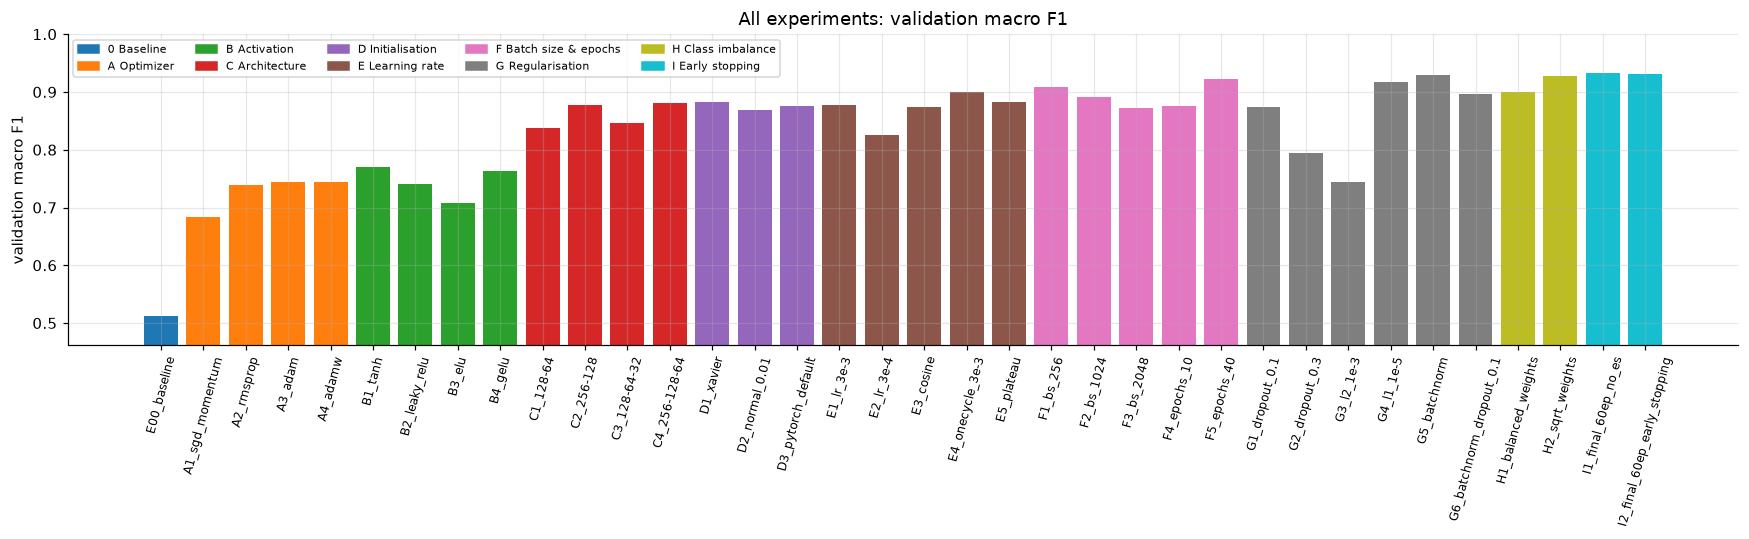

In [35]:
# Validation macro F1 of every experiment, coloured by group, in the order they were run
groups = results_df["group"].unique()
colors = dict(zip(groups, plt.cm.tab10(np.linspace(0, 1, len(groups)))))
fig, ax = plt.subplots(figsize=(16, 5))
ax.bar(results_df["exp"], results_df["val_f1_macro"], color=[colors[g] for g in results_df["group"]])
ax.set_ylim(results_df["val_f1_macro"].min() - 0.05, 1.0)
ax.set_ylabel("validation macro F1"); ax.set_title("All experiments: validation macro F1")
plt.xticks(rotation=75, fontsize=8)
handles = [plt.Rectangle((0, 0), 1, 1, color=colors[g]) for g in groups]
ax.legend(handles, groups, fontsize=7, ncol=5, loc="upper left")
plt.tight_layout(); plt.savefig("figures/all_experiments_val_f1.png"); plt.show()

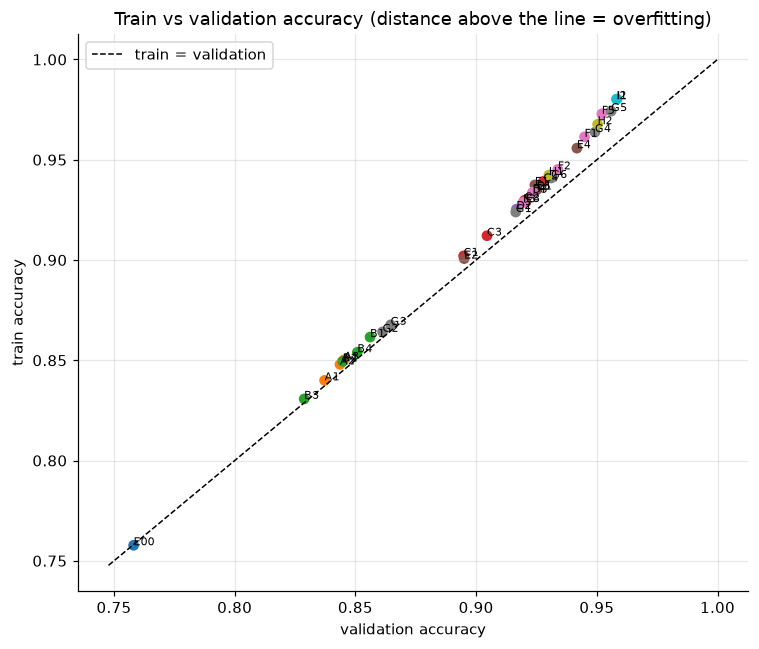

In [36]:
# Overfitting check: train accuracy vs validation accuracy for every run
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(results_df["val_acc"], results_df["train_acc"], c=[colors[g] for g in results_df["group"]])
for _, r in results_df.iterrows():
    ax.annotate(r["exp"].split("_")[0], (r["val_acc"], r["train_acc"]), fontsize=7)
lo = min(results_df["val_acc"].min(), results_df["train_acc"].min()) - 0.01
ax.plot([lo, 1], [lo, 1], "k--", lw=1, label="train = validation")
ax.set_xlabel("validation accuracy"); ax.set_ylabel("train accuracy")
ax.set_title("Train vs validation accuracy (distance above the line = overfitting)"); ax.legend()
plt.tight_layout(); plt.savefig("figures/overfitting_scatter.png"); plt.show()

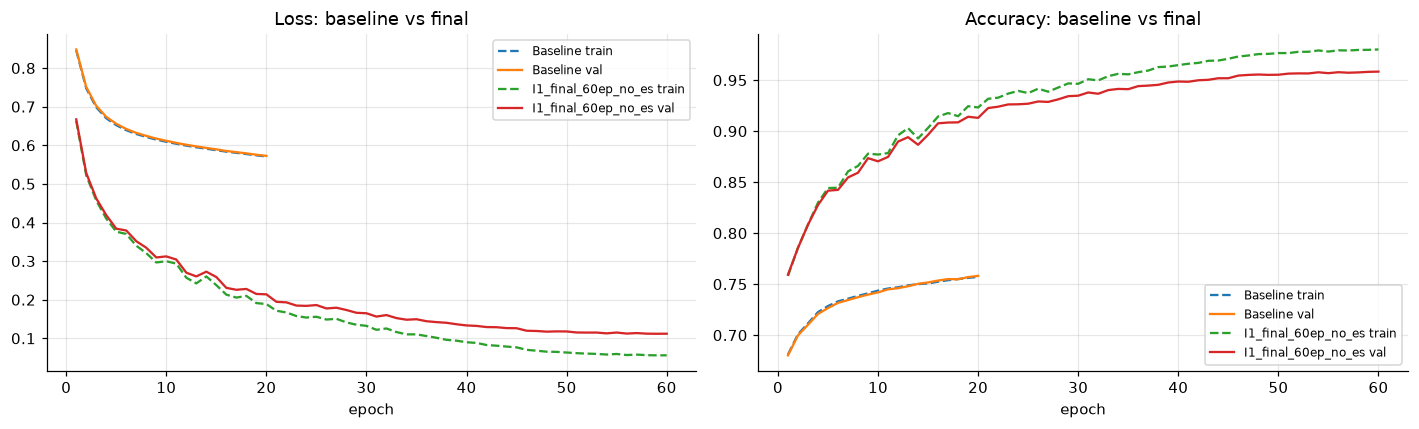

In [37]:
# Learning curves: baseline vs final model on the same axes
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, h in [("Baseline", baseline_hist), (FINAL_NAME, HISTORIES[FINAL_NAME])]:
    ep = range(1, len(h["val_loss"]) + 1)
    axes[0].plot(ep, h["train_loss"], "--", label=f"{name} train"); axes[0].plot(ep, h["val_loss"], label=f"{name} val")
    axes[1].plot(ep, h["train_acc"], "--", label=f"{name} train"); axes[1].plot(ep, h["val_acc"], label=f"{name} val")
axes[0].set_title("Loss: baseline vs final"); axes[1].set_title("Accuracy: baseline vs final")
for ax in axes:
    ax.set_xlabel("epoch"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("figures/baseline_vs_final_curves.png"); plt.show()

## 10. Conclusions, limitations, and future improvements
### 10.1 Final selection and separate test results
Across 36 experiments, I1_final_60ep_no_es has the highest validation macro F1 (0.931955), with validation
accuracy 95.84%. Its 56 -> 256 -> 128 -> 64 -> 7 architecture uses tanh, Xavier initialization, BatchNorm,
Adam, one-cycle maximum learning rate 0.003, batch 512 and 60 epochs; Dropout, L1/L2 and class weights are off.
Selection uses validation only. The held-out test set then gives accuracy 95.92%, macro precision 0.9363,
macro recall 0.9298, macro F1 0.9330, weighted F1 0.9592 and macro one-vs-rest ROC-AUC 0.9981.
The baseline test accuracy is 75.90% and macro F1 is 0.5188: improvements of 20.02 percentage points in
accuracy and 0.4142 in macro F1. Test results describe the selected model; they did not determine its settings.

### 10.2 Generalization and class-level errors
Final training accuracy/F1 are 98.02%/0.9707, versus validation 95.84%/0.9320. The 2.18-point accuracy gap
indicates some overfitting, although validation and test are close. The small baseline gap plus low scores
was underfitting; adding capacity, optimization changes and longer training was more useful than strong
regularization. Loss and accuracy curves should be read together with minority-class F1, not in isolation.
On test, Cottonwood/Willow F1 is 0.8761 (412 samples) and Aspen F1 is 0.8880 (1,424 samples), below the other
classes (0.9237-0.9656). High overall accuracy and AUC therefore do not imply uniform class performance.

### 10.3 Limitations
* One split and seed do not measure run-to-run uncertainty; tiny F1 differences may be noise.
* Greedy group-wise tuning misses interactions, and many comparisons on one validation set can overfit it.
* Several candidates bundle settings; the observed gains cannot always be assigned to one change.
* Random splits of geographically related cells may be optimistic for new regions. The dataset is limited
  to four wilderness areas in northern Colorado; this is an educational model, not a validated field system.
* Clipping can discard useful extreme-terrain information; missing-value behavior is a fallback that has
  not been evaluated on naturally missing measurements because the source dataset is complete.

### 10.4 Future improvements and reuse
Repeat promising configurations over several seeds and report uncertainty; consider spatial/grouped validation
when suitable location identifiers are available. Test finer regularization strengths, interactions and
non-neural tabular baselines within the training/validation process. Evaluate calibration if probabilities
will inform decisions. Preserve the final test split from further tuning, and use new held-out data for a
later iteration. The saved checkpoint includes fitted medians, clipping and scaling statistics;
`python predict.py examples/sample_input.csv` demonstrates inference without retraining or downloading data.